# Predicting 30-Day Hospital Readmission of Diabetic Patients

**An end-to-end, leakage-aware machine learning study on the *Diabetes 130-US Hospitals (1999–2008)* dataset**

*Authors: Ranim Rtimi & Nour Elhouda Louhichi*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/diabetes-readmission-prediction/blob/main/notebooks/diabetes_readmission_analysis.ipynb)

### TL;DR

| | Result (held-out test set, 13,998 patients) |
|---|---|
| **Task** | Flag, at discharge, diabetic patients who will be readmitted within 30 days (prevalence ≈ 9 %) |
| **Best model** | Tuned histogram gradient boosting in a leakage-safe scikit-learn pipeline |
| **Discrimination** | ROC-AUC **0.653** (95 % CI 0.638–0.670) · PR-AUC **0.179** (2× the 0.090 chance level) |
| **Operational value** | The top 10 % risk decile has a **21.2 %** readmission rate (**2.4×** the average); at a recall-oriented threshold the model catches **74 %** of readmissions |
| **Reliability** | Isotonic calibration brings the mean predicted risk from 45.9 % to **9.0 %** (observed 9.0 %); positive net benefit across threshold probabilities 3–40 % (decision curve analysis) |
| **Key drivers** | Discharge disposition and prior-year inpatient visits (permutation importance and SHAP agree); HbA1c and drugs matter little |
| **Fairness** | Similar recall across sex and race (0.73–0.79); large gap across age (0.57 under 60 vs 0.89 at 80+) driven by base rates — documented in the model card |
| **Also** | Length-of-stay regression (R² 0.44 retrospective vs 0.10 at admission) and K-Means segmentation into 3 care profiles (readmission 7.6 % → 12.0 %) |

### Contents

1. Problem framing
2. Setup
3. Data loading and integrity check
4. Data understanding
5. Exploratory data analysis
6. Data cleaning
7. Feature engineering
8. **Classification**: predicting 30-day readmission
9. **Regression**: predicting length of stay
10. **Clustering**: patient segmentation with K-Means
11. Model card, limitations and next steps

## 1. Problem framing

### 1.1 Why it matters
An **early readmission** (a patient back in hospital less than 30 days after discharge) is costly and often avoidable. In the United States, the *Hospital Readmissions Reduction Program* (HRRP) financially penalises hospitals whose 30-day readmission rates are too high. Diabetic patients are especially exposed: chronic disease, many comorbidities (cardiac, renal…) and complex treatments.

### 1.2 The question
> **At discharge, can we identify the diabetic patients at high risk of being readmitted within 30 days?**

If so, a hospital can focus enhanced follow-up (phone call, early outpatient visit, therapeutic education) on a small group of patients instead of everyone.

### 1.3 Objectives and how success is measured

| # | Objective | Task | Main metric | Section |
|---|-----------|------|-------------|---------|
| 1 | Understand the data and the factors associated with readmission | EDA | — | 4–5 |
| 2 | Make the dataset usable, justifying every decision | Cleaning, feature engineering | — | 6–7 |
| 3 | Predict readmission within 30 days at discharge | Binary classification | **PR-AUC**, recall at an operating threshold | 8 |
| 4 | Predict the length of stay (`time_in_hospital`) | Regression | MAE, RMSE, R² | 9 |
| 5 | Identify patient profiles | Clustering (K-Means) | Silhouette, external validation | 10 |
| 6 | Interpret, assess reliability and fairness, document limits | Model card | Calibration, subgroup metrics | 8, 11 |

### 1.4 Methodological principles
- **No data leakage.** One patient = one row; every learned transformation (imputation, scaling, encoding, resampling) lives inside a scikit-learn `Pipeline` fitted on training data only; hyperparameters and decision thresholds are chosen by cross-validation on the training set; the test set is touched once.
- **Metrics that match the problem.** The positive class is rare (≈ 9 %), so accuracy is misleading; we report PR-AUC, ROC-AUC, recall and precision, with bootstrap confidence intervals.
- **Beyond discrimination.** A clinical risk score must also be **calibrated**, **useful at realistic thresholds** (decision curve analysis), **explainable** (SHAP) and **fair across subgroups**. The reporting follows the spirit of the TRIPOD+AI guideline for clinical prediction models (Collins *et al.*, BMJ 2024).

## 2. Setup

All randomness is controlled with `RANDOM_STATE = 42` so every result is reproducible. Missing optional packages (`imbalanced-learn`, `shap`) are installed automatically.

In [1]:
# --- Install optional dependencies if missing (useful on Colab) ---
import importlib, subprocess, sys, warnings
warnings.filterwarnings("ignore")
for pkg, mod in [("imbalanced-learn", "imblearn"), ("shap", "shap")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, time, warnings, zipfile, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupShuffleSplit, cross_validate,
                                     cross_val_predict, cross_val_score, RandomizedSearchCV, validation_curve)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, fbeta_score, roc_auc_score, roc_curve,
                             average_precision_score, precision_recall_curve, classification_report,
                             brier_score_loss, mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score)
import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import shap
import joblib

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"      # also silences parallel workers (n_jobs=-1)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 100,
                     "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

FIG_DIR = os.path.join("reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    # Save the current figure for the project README (reports/figures/<name>.png)
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} "
      f"| imbalanced-learn {imblearn.__version__} | shap {shap.__version__}")

pandas 2.2.3 | numpy 2.5.3 | scikit-learn 1.6.1 | imbalanced-learn 0.13.0 | shap 0.54.1


## 3. Data loading and integrity check

The dataset was published in 2014 by Strack *et al.* on the UCI Machine Learning Repository (DOI: 10.24432/C5230J). It describes **101,766 hospital encounters** of diabetic patients in **130 US hospitals** between 1999 and 2008. Encounters were selected with five criteria: inpatient stay, any diabetes diagnosis, length of stay of 1 to 14 days, laboratory tests performed and medication administered.

The loader below (1) reuses a local copy if present, (2) otherwise downloads the official UCI archive, (3) falls back to a GitHub mirror if UCI is unreachable, and (4) **verifies integrity** (expected shape and target counts).

The CSV is read with `keep_default_na=False`: by default pandas would turn the string `"None"` into a missing value, but here `A1Cresult = "None"` means **"test not performed"**, which is information in itself. True missing values are coded `"?"` and are handled explicitly.

In [2]:
DATA_DIR = "data"
CSV_PATH = os.path.join(DATA_DIR, "diabetic_data.csv")
URL_UCI = ("https://archive.ics.uci.edu/static/public/296/"
           "diabetes+130-us+hospitals+for+years+1999-2008.zip")
URL_MIRROR = "https://raw.githubusercontent.com/lugooe/Diabetes/main/diabetic_data.csv"

def download_dataset():
    # Download diabetic_data.csv (UCI first, then mirror) and return the source used.
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists(CSV_PATH):
        return "local cache"
    try:
        with urllib.request.urlopen(URL_UCI, timeout=60) as r:
            archive = zipfile.ZipFile(io.BytesIO(r.read()))
        name = [n for n in archive.namelist() if n.endswith("diabetic_data.csv")][0]
        with open(CSV_PATH, "wb") as f:
            f.write(archive.read(name))
        return "UCI Machine Learning Repository"
    except Exception as e:
        print(f"UCI unreachable ({type(e).__name__}) -> using GitHub mirror")
        urllib.request.urlretrieve(URL_MIRROR, CSV_PATH)
        return "GitHub mirror"

source = download_dataset()
raw = pd.read_csv(CSV_PATH, keep_default_na=False, low_memory=False)

# Integrity check: the file must match the published dataset exactly
assert raw.shape == (101766, 50), f"Unexpected shape: {raw.shape}"
assert raw["readmitted"].value_counts().to_dict() == {"NO": 54864, ">30": 35545, "<30": 11357}
print(f"Source: {source}")
print(f"Dataset loaded and verified: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

UCI unreachable (URLError) -> using GitHub mirror


Source: GitHub mirror
Dataset loaded and verified: 101,766 rows x 50 columns


## 4. Data understanding

### 4.1 First look

In [3]:
display(raw.head())
raw.info()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

### 4.2 Data dictionary

The `*_id` columns are **codes** representing **categories**: they are nominal variables, not numbers (code 7 is not "greater" than code 1).

| Family | Variables | Type |
|--------|-----------|------|
| Identifiers | `encounter_id` (stay), `patient_nbr` (patient) | identifier |
| Demographics | `race`, `gender`, `age` (10-year bands), `weight` | categorical (age is ordinal) |
| Admission / discharge | `admission_type_id`, `admission_source_id`, `discharge_disposition_id`, `payer_code`, `medical_specialty` | nominal (codes) |
| Stay | `time_in_hospital` (days), `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses` | numeric (counts) |
| Prior year history | `number_outpatient`, `number_emergency`, `number_inpatient` | numeric (counts) |
| Diagnoses | `diag_1` (primary), `diag_2`, `diag_3` — ICD-9 codes | high-cardinality categorical |
| Lab results | `max_glu_serum` (glucose), `A1Cresult` (HbA1c) | ordinal (`None` = not measured) |
| Treatment | 23 medication columns (`metformin`, `insulin`…): `No` / `Steady` / `Up` / `Down`, plus `change`, `diabetesMed` | categorical |
| **Target** | `readmitted`: `<30`, `>30`, `NO` | categorical |

### 4.3 Descriptive statistics of numeric variables

In [4]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
desc = raw[num_cols].describe().T
desc["median"] = raw[num_cols].median()
desc["skewness"] = raw[num_cols].skew()
display(desc)

,count,mean,std,min,25%,50%,75%,max,median,skewness
time_in_hospital,"101,766.0000",4.3960,2.9851,1.0000,2.0000,4.0000,6.0000,14.0000,4.0000,1.1340
num_lab_procedures,"101,766.0000",43.0956,19.6744,1.0000,31.0000,44.0000,57.0000,132.0000,44.0000,-0.2365
num_procedures,"101,766.0000",1.3397,1.7058,0.0000,0.0000,1.0000,2.0000,6.0000,1.0000,1.3164
num_medications,"101,766.0000",16.0218,8.1276,1.0000,10.0000,15.0000,20.0000,81.0000,15.0000,1.3267
number_outpatient,"101,766.0000",0.3694,1.2673,0.0000,0.0000,0.0000,0.0000,42.0000,0.0000,8.8330
number_emergency,"101,766.0000",0.1978,0.9305,0.0000,0.0000,0.0000,0.0000,76.0000,0.0000,22.8556
number_inpatient,"101,766.0000",0.6356,1.2629,0.0000,0.0000,0.0000,1.0000,21.0000,0.0000,3.6141
number_diagnoses,"101,766.0000",7.4226,1.9336,1.0000,6.0000,8.0000,9.0000,16.0000,8.0000,-0.8767


**Reading.**
- `time_in_hospital`: mean 4.4 days, median 4, range 1–14 (a selection criterion). Mean > median (skewness 1.13): most stays are short, a few are long.
- `num_lab_procedures` is the only roughly **symmetric** variable (mean 43.1 ≈ median 44).
- `number_outpatient`, `number_emergency` and `number_inpatient` have a **median of 0** and very strong skewness (8.8, 22.9, 3.6): most patients had no hospital contact in the previous year, while a minority had many (up to 76 emergency visits). These tails matter for outlier handling and for clustering (log transform).

### 4.4 Categorical variables: levels and "disguised" missing values

In [5]:
cat_cols = raw.select_dtypes(exclude="number").columns.tolist()
cat_summary = pd.DataFrame({
    "n_levels": raw[cat_cols].nunique(),
    "most_frequent": raw[cat_cols].apply(lambda s: s.value_counts().index[0]),
    "most_frequent_%": raw[cat_cols].apply(lambda s: 100 * s.value_counts(normalize=True).iloc[0]),
    "n_'?'": (raw[cat_cols] == "?").sum(),
}).sort_values("n_levels", ascending=False)
display(cat_summary)
for c in ["race", "gender", "age", "A1Cresult", "max_glu_serum", "readmitted"]:
    print(f"{c:15s} ->", list(raw[c].unique()))

,n_levels,most_frequent,most_frequent_%,n_'?'
diag_3,790,250,11.3545,1423
diag_2,749,276,6.6348,358
diag_1,717,428,6.7429,21
medical_specialty,73,?,49.0822,49949
payer_code,18,?,39.5574,40256
age,10,[70-80),25.6156,0
weight,10,?,96.8585,98569
race,6,Caucasian,74.7784,2273
glyburide-metformin,4,No,99.3063,0
max_glu_serum,4,None,94.7468,0


race            -> ['Caucasian', 'AfricanAmerican', '?', 'Other', 'Asian', 'Hispanic']
gender          -> ['Female', 'Male', 'Unknown/Invalid']
age             -> ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']
A1Cresult       -> ['None', '>7', '>8', 'Norm']
max_glu_serum   -> ['None', '>300', 'Norm', '>200']
readmitted      -> ['NO', '>30', '<30']


**Reading.**
- **Very high cardinality**: `diag_1/2/3` have 717–790 distinct codes and `medical_specialty` 73 levels → grouping is needed before encoding (section 7).
- **Disguised missing values**: `info()` reports no nulls because missing values are coded `"?"`. `weight` is 96.9 % empty, `medical_specialty` 49.1 %, `payer_code` 39.6 %, `race` 2.2 %.
- **Quasi-constant variables**: several drugs are `No` in more than 99 % of encounters, and some take a single value.
- `A1Cresult = "None"` (83.3 %) and `max_glu_serum = "None"` (94.7 %) mean "test not performed".
- `gender` contains an `Unknown/Invalid` level: an inconsistency to fix.

## 5. Exploratory data analysis

EDA is **descriptive** and uses the full dataset. No learned parameter (imputation median, scaling statistics, encoding levels…) is computed from the test set: all of them are learned inside pipelines on training data (section 8).

### 5.1 Target distribution

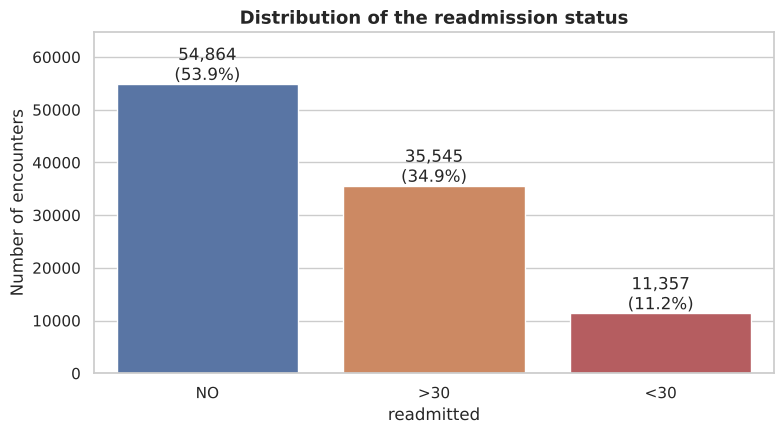

In [6]:
counts = raw["readmitted"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=["#4C72B0", "#DD8452", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 800, f"{v:,}\n({v / counts.sum():.1%})", ha="center")
ax.set_title("Distribution of the readmission status")
ax.set_xlabel("readmitted"); ax.set_ylabel("Number of encounters"); ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.show()

**Reading.** 53.9 % of encounters are followed by no readmission, 34.9 % by a readmission after 30 days and **11.2 % by a readmission within 30 days** — the class we care about is the smallest one.

### 5.2 Binary target

The business question concerns readmission **within 30 days**, so:

$$\texttt{readmitted\_30d} = \begin{cases} 1 & \text{if readmitted} = \texttt{"<30"} \\ 0 & \text{if readmitted} \in \{\texttt{"NO"}, \texttt{">30"}\} \end{cases}$$

- Readmissions **after 30 days** are not the target: they reflect the natural course of the disease more than the quality of discharge, and they are not penalised. They join the negative class.
- **Consequence 1**: the positive class is a **minority** (≈ 11 % of encounters) → an **imbalanced** problem in which accuracy is misleading.
- **Consequence 2**: the negative class is **heterogeneous** (it includes patients readmitted at day 31, very close to positives). The class boundary is fuzzy, which caps achievable performance.

In [7]:
raw["readmitted_30d"] = (raw["readmitted"] == "<30").astype(int)
print(raw["readmitted_30d"].value_counts().rename({0: "0 = not readmitted <30d", 1: "1 = readmitted <30d"}))
print(f"\n30-day readmission rate (all encounters): {raw['readmitted_30d'].mean():.2%}")

readmitted_30d
0 = not readmitted <30d    90409
1 = readmitted <30d        11357
Name: count, dtype: int64

30-day readmission rate (all encounters): 11.16%


### 5.3 Distributions of numeric variables
For integer counts, one bin per value avoids binning artefacts.

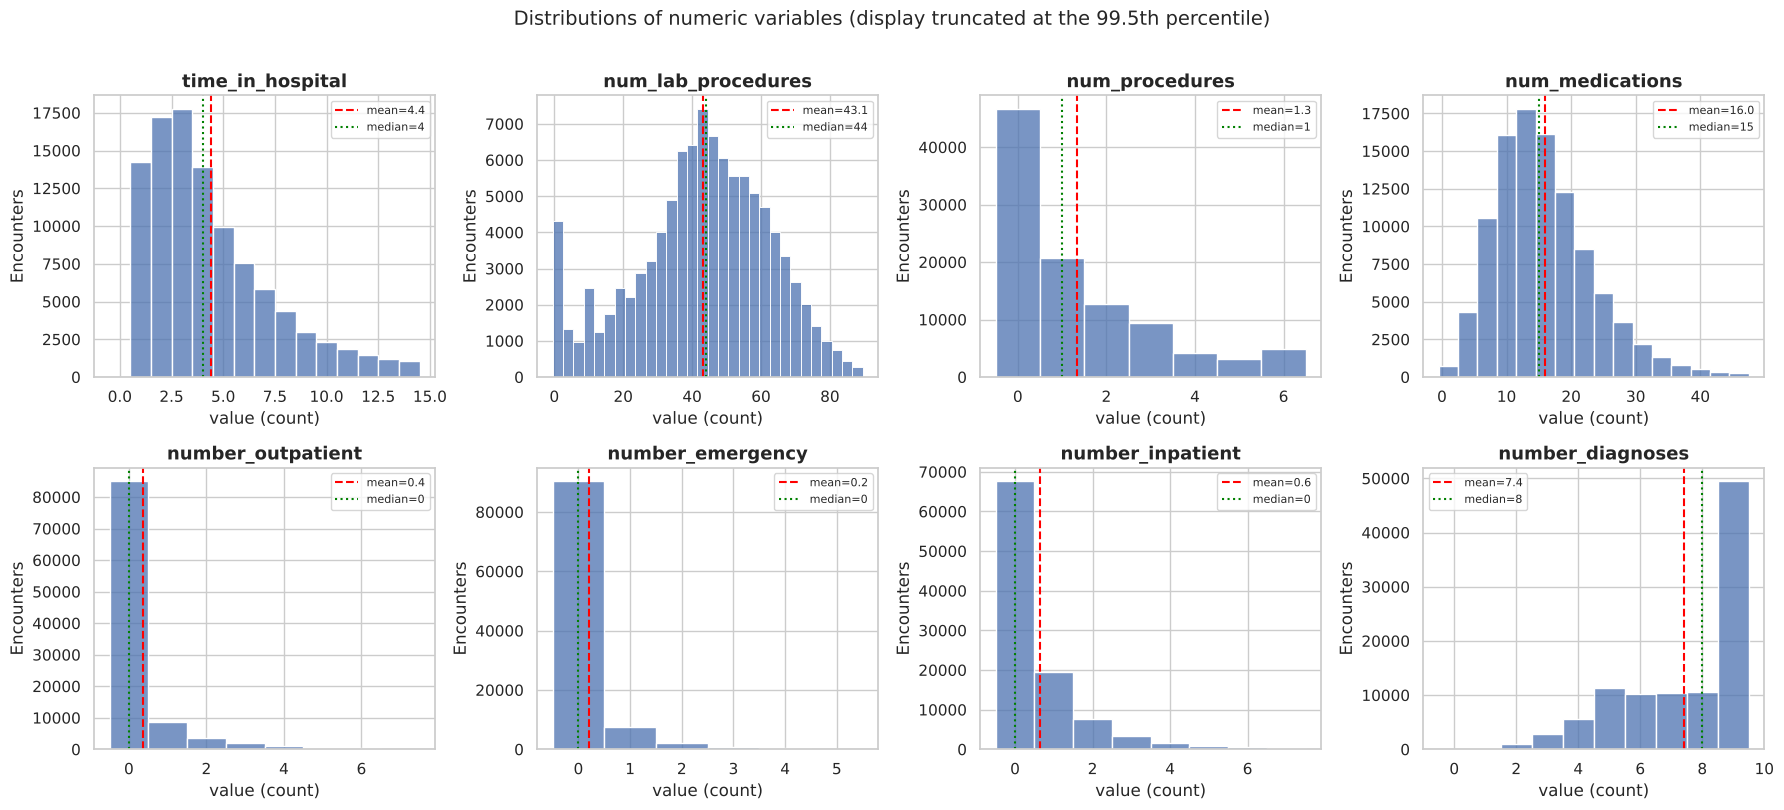

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    vmax = int(raw[col].quantile(0.995))      # display truncated at the 99.5th percentile
    sns.histplot(raw.loc[raw[col] <= vmax, col], bins=np.arange(-0.5, vmax + 1.5, 1 if vmax < 30 else 3),
                 ax=ax, color="#4C72B0")
    ax.axvline(raw[col].mean(), color="red", ls="--", label=f"mean={raw[col].mean():.1f}")
    ax.axvline(raw[col].median(), color="green", ls=":", label=f"median={raw[col].median():.0f}")
    ax.set_title(col); ax.set_xlabel("value (count)"); ax.set_ylabel("Encounters"); ax.legend(fontsize=8)
plt.suptitle("Distributions of numeric variables (display truncated at the 99.5th percentile)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

**Reading.**
- `time_in_hospital`, `num_medications` and `num_procedures` are **right-skewed** and unimodal.
- `num_lab_procedures` is bell-shaped around 45 but shows an **isolated spike at very small values** (1–2 tests, more than 4,000 encounters), probably encounters where very few lab results were recorded — a data-collection subgroup, not an error.
- The three history variables are concentrated at 0.
- `number_diagnoses` has a **massive spike at 9**: the source system most likely capped recorded diagnoses at 9 for part of the period. This **collection artefact** limits the information carried by this variable.

### 5.4 Distributions by outcome

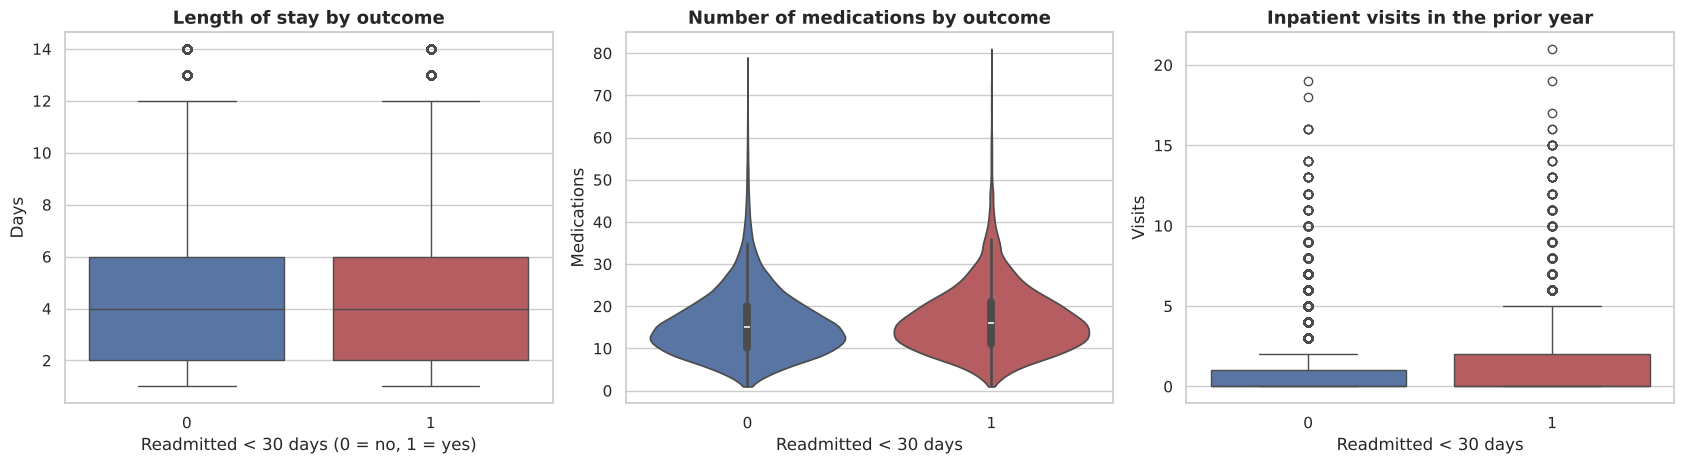

readmitted_30d,"median, not readmitted","median, readmitted"
time_in_hospital,4.0000,4.0000
num_lab_procedures,44.0000,45.0000
num_procedures,1.0000,1.0000
num_medications,15.0000,16.0000
number_outpatient,0.0000,0.0000
number_emergency,0.0000,0.0000
number_inpatient,0.0000,0.0000
number_diagnoses,8.0000,9.0000


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.boxplot(data=raw, x="readmitted_30d", y="time_in_hospital", ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Length of stay by outcome"); axes[0].set_xlabel("Readmitted < 30 days (0 = no, 1 = yes)"); axes[0].set_ylabel("Days")
sns.violinplot(data=raw, x="readmitted_30d", y="num_medications", ax=axes[1], palette=["#4C72B0", "#C44E52"], cut=0)
axes[1].set_title("Number of medications by outcome"); axes[1].set_xlabel("Readmitted < 30 days"); axes[1].set_ylabel("Medications")
sns.boxplot(data=raw, x="readmitted_30d", y="number_inpatient", ax=axes[2], palette=["#4C72B0", "#C44E52"])
axes[2].set_title("Inpatient visits in the prior year"); axes[2].set_xlabel("Readmitted < 30 days"); axes[2].set_ylabel("Visits")
plt.tight_layout(); plt.show()
display(raw.groupby("readmitted_30d")[num_cols].median().T.rename(columns={0: "median, not readmitted", 1: "median, readmitted"}))

**Reading.**
- **Length of stay**: the two boxes are almost identical (median 4 days in both groups).
- **Medications**: the violin of readmitted patients is very slightly shifted up (median 16 vs 15).
- **Prior inpatient visits**: the clearest difference — the third quartile moves from 1 to 2 and the whisker from 2 to 5. Readmitted patients have a **heavier hospital history**.

No single numeric variable separates the groups; distributions overlap heavily. Prediction will require **combining** many weak signals.

### 5.5 Readmission rate by key factors
For a categorical factor we compare the **rate** of readmission per level, not raw counts. The dashed red line is the overall rate.

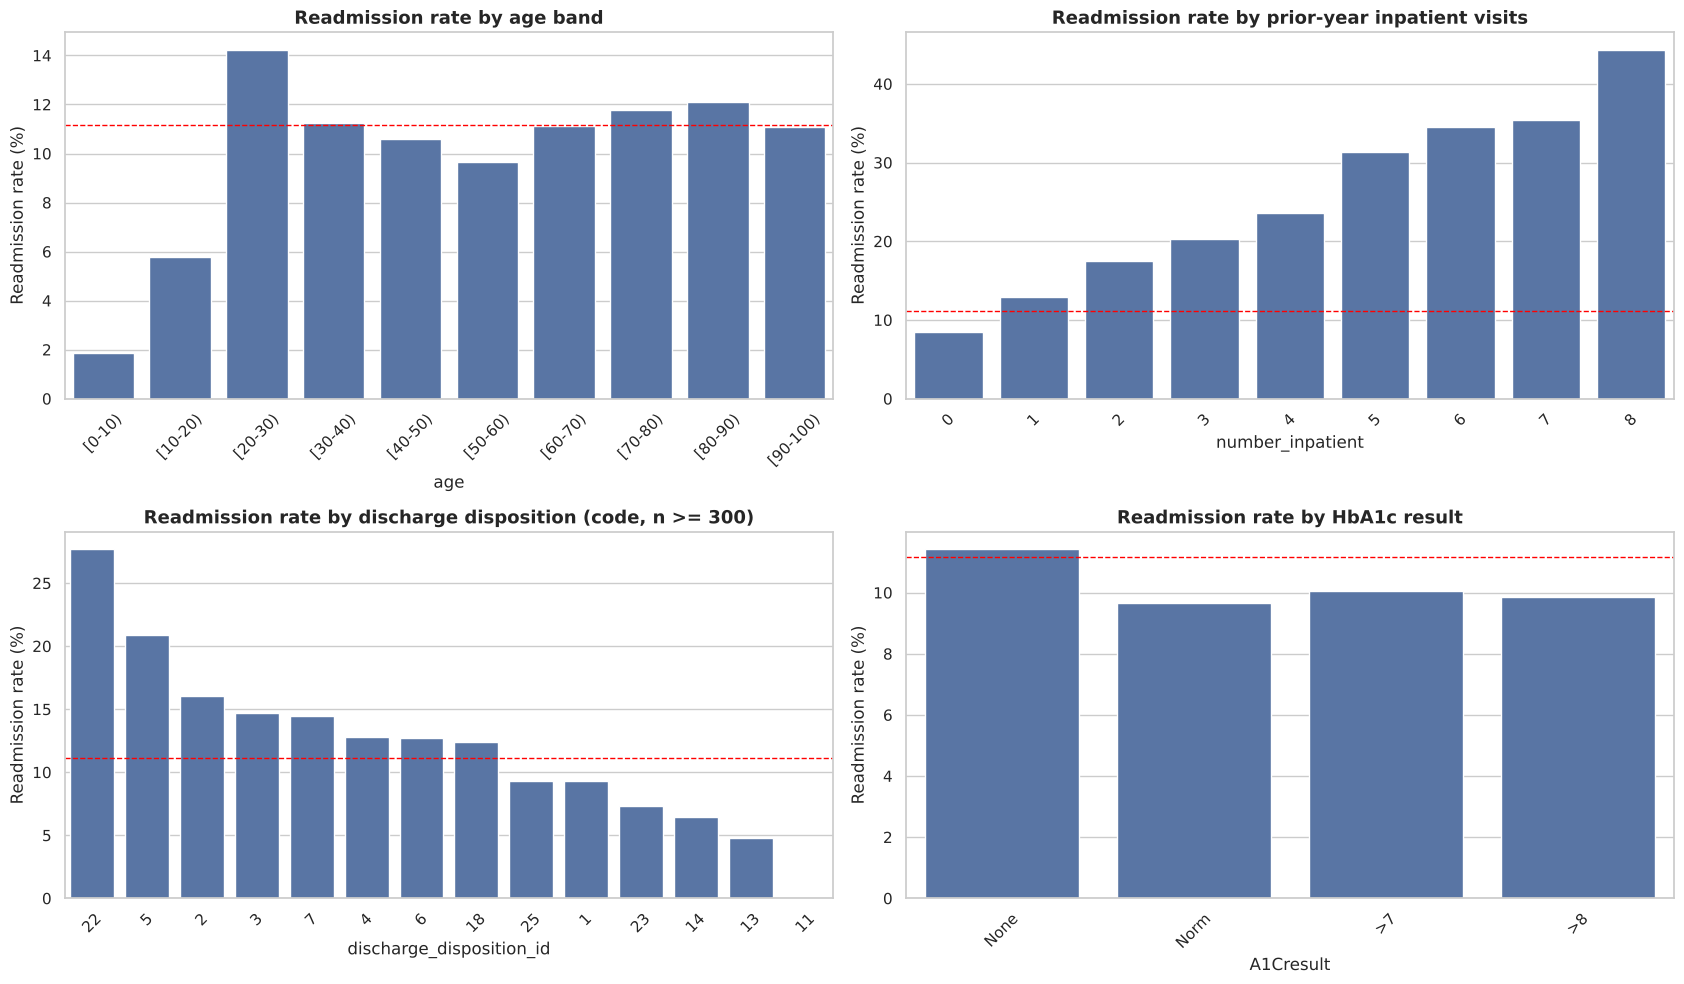

Rate by prior-year inpatient visits:


number_inpatient,0,1,2,3,4,5,6,7,8
mean,0.0844,0.1292,0.1743,0.2029,0.2361,0.3140,0.3458,0.3545,0.4437
size,"67,630.0000","19,521.0000","7,566.0000","3,411.0000","1,622.0000",812.0000,480.0000,268.0000,151.0000


In [10]:
def rate_by(col, data=raw, ax=None, order=None, min_n=100, title=None):
    # Bar chart of the 30-day readmission rate per level (levels with n >= min_n).
    g = data.groupby(col)["readmitted_30d"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    g = g.loc[[o for o in order if o in g.index]] if order is not None else g.sort_values("mean", ascending=False)
    sns.barplot(x=g.index.astype(str), y=g["mean"] * 100, ax=ax, color="#4C72B0")
    ax.axhline(data["readmitted_30d"].mean() * 100, color="red", ls="--", lw=1)
    ax.set_title(title or f"30-day readmission rate by {col}")
    ax.set_ylabel("Readmission rate (%)"); ax.set_xlabel(col); ax.tick_params(axis="x", rotation=45)
    return g

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
g_age = rate_by("age", ax=axes[0, 0], order=sorted(raw["age"].unique()), title="Readmission rate by age band")
g_inp = rate_by("number_inpatient", ax=axes[0, 1], order=list(range(0, 9)), title="Readmission rate by prior-year inpatient visits")
g_dis = rate_by("discharge_disposition_id", ax=axes[1, 0], min_n=300, title="Readmission rate by discharge disposition (code, n >= 300)")
g_a1c = rate_by("A1Cresult", ax=axes[1, 1], order=["None", "Norm", ">7", ">8"], title="Readmission rate by HbA1c result")
plt.tight_layout(); save_fig("eda_readmission_rates"); plt.show()
print("Rate by prior-year inpatient visits:")
display(g_inp.T)

**Reading.**
- **Prior inpatient visits**: a **strong, monotonic** relationship — 8.4 % with no visit in the previous year, 12.9 % with one, 17.4 % with two, 20.3 % with three and above 30 % from five. The clearest risk factor in the EDA.
- **Discharge disposition**: highly discriminating. Discharge to **rehabilitation** (code 22: 27.7 %), **another care institution** (code 5: 20.9 %) or **another short-term hospital** (code 2: 16.1 %) is far riskier than **home** (code 1: 9.3 %). Codes 11 (death), 13 and 14 (hospice) show near-zero rates, which justifies excluding them (section 6).
- **Age**: low rates under 20, then 10–12 %. The 14.2 % peak at [20-30) rests on only 1,657 encounters, and the youngest bands are tiny ([0-10): 161 encounters) — rates on small groups are unreliable.
- **HbA1c**: small differences (9.7–10.0 % when measured, 11.4 % when not). Not measuring HbA1c is slightly associated with more readmissions, in line with the reference study (Strack *et al.*, 2014) — an **association**, not a causal effect.

### 5.6 Two-way view: age × HbA1c

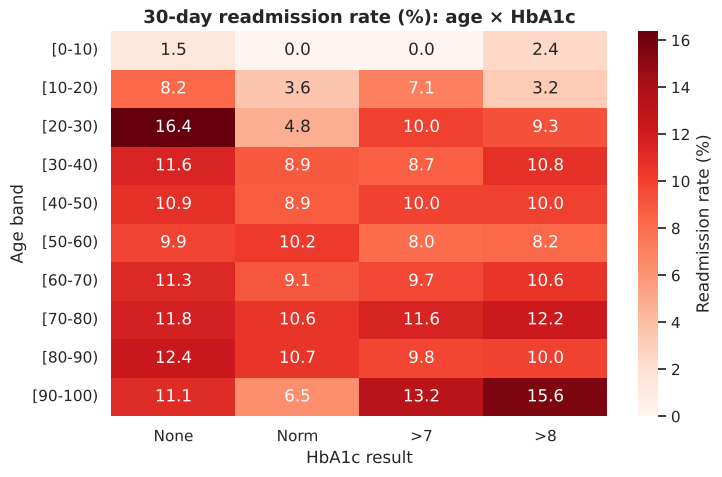

Cell sizes for the youngest bands:


A1Cresult,>7,>8,None,Norm
age,,,,
[0-10),2,82,68,9
[10-20),14,280,341,56
[20-30),30,334,1209,84


In [11]:
two_way = raw.groupby(["age", "A1Cresult"])["readmitted_30d"].agg(["mean", "size"])
pivot = two_way["mean"].unstack("A1Cresult")[["None", "Norm", ">7", ">8"]] * 100
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Readmission rate (%)"})
plt.title("30-day readmission rate (%): age × HbA1c"); plt.xlabel("HbA1c result"); plt.ylabel("Age band")
plt.show()
print("Cell sizes for the youngest bands:")
display(two_way["size"].unstack("A1Cresult").head(3))

**Reading.** No clear gradient appears: in most adult bands rates stay between 8 % and 12 % whatever the HbA1c result. The extreme cells (16.4 % for [20-30) without test, 15.6 % for [90-100) with HbA1c > 8, 0 % for children) rest on **very small counts** — mostly sampling noise. A rate must always be read **with its sample size**.

### 5.7 Correlations
We use **Spearman** rank correlation: the variables are highly skewed counts, and Spearman captures monotonic relationships while being robust to extreme values.

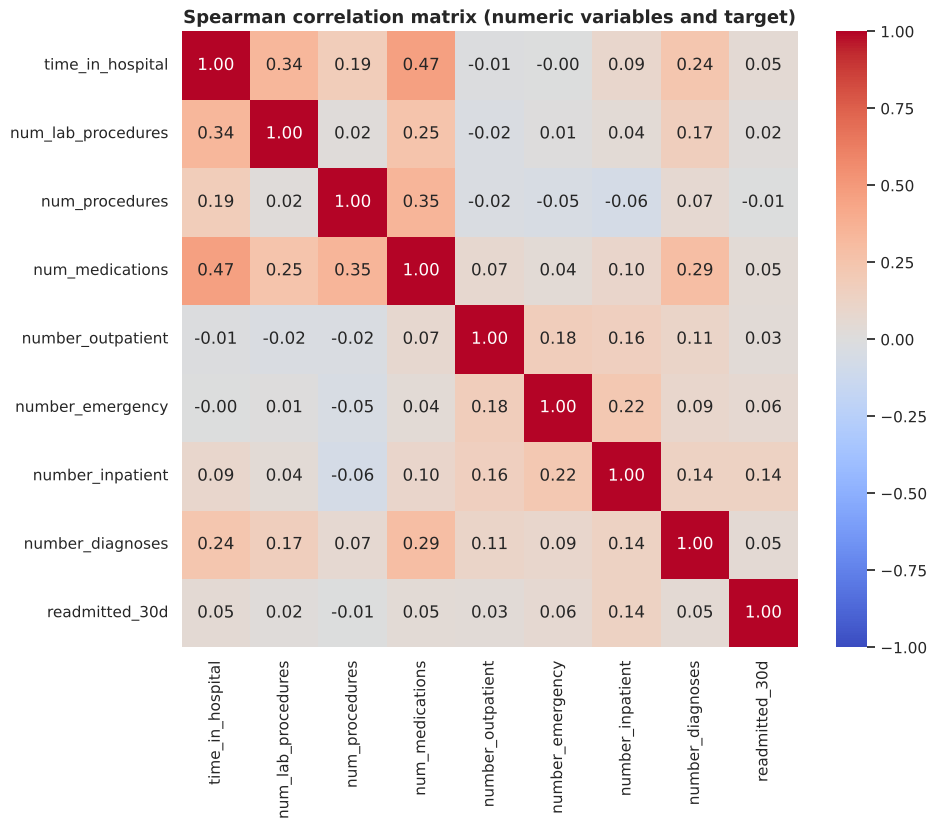

Spearman correlation with the target:
number_inpatient      0.1380
number_emergency      0.0630
time_in_hospital      0.0510
number_diagnoses      0.0470
num_medications       0.0450
number_outpatient     0.0340
num_lab_procedures    0.0210
num_procedures       -0.0060
Name: readmitted_30d, dtype: float64


In [12]:
corr = raw[num_cols + ["readmitted_30d"]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Spearman correlation matrix (numeric variables and target)")
plt.show()
print("Spearman correlation with the target:")
print(corr["readmitted_30d"].drop("readmitted_30d").sort_values(ascending=False).round(3))

**Reading.**
- **Between predictors**: the strongest link is `time_in_hospital`–`num_medications` (0.47), then `num_procedures`–`num_medications` (0.35) and `time_in_hospital`–`num_lab_procedures` (0.34). No correlation exceeds 0.5: little redundancy, all variables can be kept.
- **With the target**: all **weak** (max 0.14 for `number_inpatient`).
- **Caveat**: a weak correlation does not mean "no relationship" — it only measures monotonic, one-variable-at-a-time links; tree ensembles can exploit **interactions**. Conversely, `time_in_hospital`–`num_medications` does not imply causality: both depend on illness severity (confounding).

## 6. Data cleaning

We first **diagnose** the four families of data-quality issues (duplicates, inconsistencies, missing values, outliers) before fixing anything, then treat them in a deliberate order: exact duplicates → inconsistencies → identifier duplicates → outliers → missing values.

### 6.1 Diagnosis

In [13]:
df0 = raw.copy()
UNKNOWN_CODES = {   # "NULL / Not Mapped / Not Available / Unknown" codes, from the UCI IDs_mapping.csv file
    "admission_type_id": [5, 6, 8],
    "discharge_disposition_id": [18, 25, 26],
    "admission_source_id": [9, 15, 17, 20, 21],
}
EXPIRED_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
diagnosis = pd.DataFrame({
    "Family": ["Duplicates", "Duplicates", "Inconsistencies", "Inconsistencies", "Inconsistencies",
               "Missing values", "Outliers"],
    "Column(s) / rule": [
        "fully identical rows",
        "repeated patient_nbr (several encounters of one patient)",
        "gender = 'Unknown/Invalid'",
        "*_id codes meaning 'unknown' (disguised missing values)",
        "patients who died or went to hospice (cannot be readmitted)",
        "'?' in weight, payer_code, medical_specialty, race, diag_1/2/3",
        "extreme counts (IQR method, see 6.5)",
    ],
    "Count": [
        df0.duplicated().sum(),
        df0["patient_nbr"].duplicated().sum(),
        (df0["gender"] == "Unknown/Invalid").sum(),
        sum(df0[c].isin(v).sum() for c, v in UNKNOWN_CODES.items()),
        df0["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE).sum(),
        (df0 == "?").sum().sum(),
        "see 6.5",
    ],
})
display(diagnosis)
print("encounter_id unique?", df0["encounter_id"].is_unique)

,Family,Column(s) / rule,Count
0,Duplicates,fully identical rows,0
1,Duplicates,repeated patient_nbr (several encounters of on...,30248
2,Inconsistencies,gender = 'Unknown/Invalid',3
3,Inconsistencies,*_id codes meaning 'unknown' (disguised missin...,22143
4,Inconsistencies,patients who died or went to hospice (cannot b...,2423
5,Missing values,"'?' in weight, payer_code, medical_specialty, ...",192849
6,Outliers,"extreme counts (IQR method, see 6.5)",see 6.5


encounter_id unique? True


**Reading.** **No exact duplicates** and unique `encounter_id`s, but **30,248 encounters** belong to a patient already present. Also: 3 invalid genders, 22,143 disguised "unknown" codes in the `*_id` columns, 2,423 encounters ending in death or hospice, and 192,849 `"?"` cells (98,569 of them in `weight` alone).

### 6.2 Duplicates and the patient-level problem

`encounter_id` is unique, but `patient_nbr` is not: these are **several encounters of the same patient**, not data-entry errors. They nevertheless create three methodological problems:

- **Non-independence**: models assume independent observations; encounters of the same patient are correlated.
- **Data leakage**: if a patient has one encounter in train and another in test, the model effectively "recognises" the patient and test performance may be **overestimated** (tested empirically in section 8.7).
- **Link with the target**: a readmitted patient generates, by definition, an extra encounter, so multi-encounter patients are over-represented among positives.

**Decision**: keep **the first encounter of each patient** (smallest `encounter_id`, which follows chronological order), as in the reference study (Strack *et al.*, 2014). One patient = one row, which makes a stratified random split valid. History is still available through `number_inpatient`, `number_emergency` and `number_outpatient`.

In [14]:
print("Exact duplicate rows:", df0.duplicated().sum())
enc_per_patient = df0["patient_nbr"].value_counts()
print(f"Distinct patients: {df0['patient_nbr'].nunique():,} for {len(df0):,} encounters")
print("Number of encounters per patient:")
print(enc_per_patient.value_counts().sort_index().head(8).rename("n_patients"))

df0["n_encounters_patient"] = df0["patient_nbr"].map(enc_per_patient)
rate = df0.groupby(pd.cut(df0["n_encounters_patient"], [0, 1, 2, 3, 5, 100],
                          labels=["1", "2", "3", "4-5", "6+"]), observed=True)["readmitted_30d"].mean()
print("\n30-day readmission rate by total number of encounters of the patient:")
print((rate * 100).round(1).astype(str) + " %")
df0 = df0.drop(columns="n_encounters_patient")

Exact duplicate rows: 0
Distinct patients: 71,518 for 101,766 encounters
Number of encounters per patient:
count
1    54745
2    10434
3     3328
4     1421
5      717
6      346
7      207
8      111
Name: n_patients, dtype: int64

30-day readmission rate by total number of encounters of the patient:
n_encounters_patient
1       4.0 %
2      15.0 %
3      19.2 %
4-5    22.4 %
6+     30.1 %
Name: readmitted_30d, dtype: object


**Reading.** 71,518 patients for 101,766 encounters: 54,745 patients have a single encounter, some have 8 or more. The readmission rate climbs from **4.0 %** for single-encounter patients to **30.1 %** for patients with 6+ encounters. Keeping every encounter would **entangle the target with the structure of the dataset**, so only the first encounter per patient is kept.

### 6.3 Inconsistencies

| Issue | Decision | Rationale |
|-------|----------|-----------|
| `gender = "Unknown/Invalid"` (3 rows) | drop | negligible, not interpretable |
| `*_id` codes meaning "NULL", "Not Mapped", "Not Available" | set to missing | **disguised missing values**: left as a regular category, the model would treat them as a real admission type |
| `discharge_disposition_id` in {11, 19, 20, 21} (death) and {13, 14} (hospice) | drop | **business rule**: a deceased patient cannot be readmitted; keeping them adds "certain negatives" that the model would learn trivially |
| Rule `1 ≤ time_in_hospital ≤ 14` | check | dataset construction criterion |
| Negative counts | check | impossible by definition |

In [15]:
print("time_in_hospital outside [1, 14]:", (~df0["time_in_hospital"].between(1, 14)).sum())
print("negative counts:", (df0[num_cols] < 0).sum().sum())
print("expired / hospice discharges:", df0["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE).sum())
for c, v in UNKNOWN_CODES.items():
    print(f"{c:26s}: {df0[c].isin(v).sum():6,} 'unknown' codes -> will become missing")

time_in_hospital outside [1, 14]: 0
negative counts: 0
expired / hospice discharges: 2423
admission_type_id         : 10,396 'unknown' codes -> will become missing
discharge_disposition_id  :  4,680 'unknown' codes -> will become missing
admission_source_id       :  7,067 'unknown' codes -> will become missing


### 6.4 Missing values

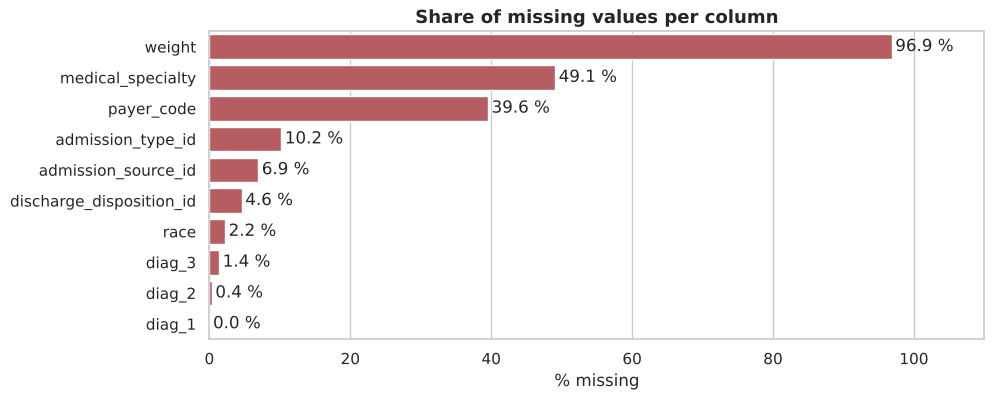

Rows left after dropna(): 1,036 of 101,766


In [16]:
tmp = df0.replace("?", np.nan)
for c, v in UNKNOWN_CODES.items():
    tmp[c] = tmp[c].mask(tmp[c].isin(v))
miss = (tmp.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(10, 4))
ax = sns.barplot(x=miss.values, y=miss.index, color="#C44E52")
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center")
plt.title("Share of missing values per column"); plt.xlabel("% missing"); plt.ylabel("")
plt.xlim(0, 110); plt.show()
print(f"Rows left after dropna(): {len(tmp.dropna()):,} of {len(tmp):,}")

**Strategy, one decision per variable:**

| Variable | % missing | Decision | Rationale |
|----------|-----------|----------|-----------|
| `weight` | ≈ 97 % | **dropped** | almost empty, no credible imputation |
| `payer_code` | ≈ 40 % | **dropped** | administrative (payment method), no direct clinical meaning, very incomplete |
| `medical_specialty` | ≈ 49 % | **"Unknown" category** | too informative to drop; a missing specialty is itself a signal |
| `race`, `diag_1/2/3` | < 3 % | **"Unknown" category** | few rows, categorical |
| unknown `*_id` codes | varies | **"Unknown" category** | same reasoning |
| `A1Cresult`, `max_glu_serum` = `"None"` | — | **kept as a level** | not missing: "test not performed" is an indicator of care |

`dropna()` is ruled out: it would remove almost every row (because of `weight`). Median imputation of numeric features, if ever needed, happens inside the modelling pipelines.

### 6.5 Outliers
Two classic detectors: the **interquartile range (IQR)** rule and the **z-score**.

,IQR_low,IQR_high,n_outside_IQR,%_outside_IQR,n_|z|>3,min,max
variable,,,,,,,
time_in_hospital,-4.0000,12.0000,2252,2.2129,1042,1,14
num_lab_procedures,-8.0000,96.0000,143,0.1405,43,1,132
num_procedures,-3.0000,5.0000,4954,4.8680,0,0,6
num_medications,-5.0000,35.0000,2557,2.5126,1361,1,81
number_outpatient,0.0000,0.0000,16739,16.4485,1457,0,42
number_emergency,0.0000,0.0000,11383,11.1855,1664,0,76
number_inpatient,-1.5000,2.5000,7049,6.9267,2016,0,21
number_diagnoses,1.5000,13.5000,281,0.2761,281,1,16


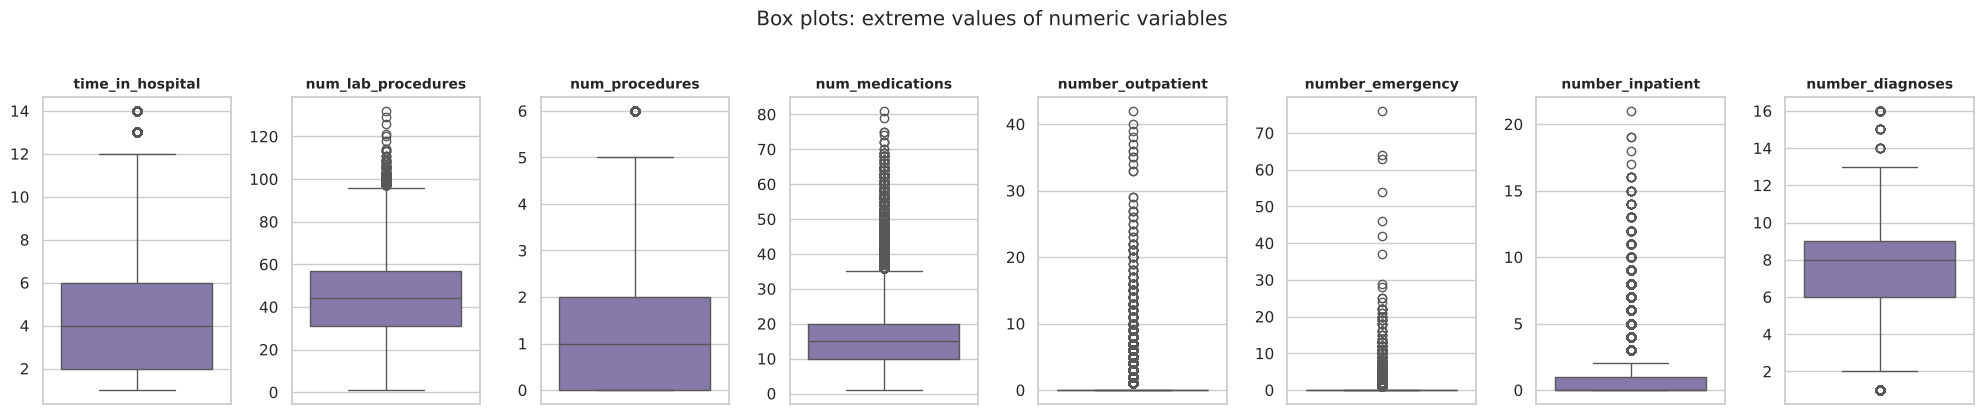

In [17]:
def iqr_bounds(s):
    # Return (Q1 - 1.5*IQR, Q3 + 1.5*IQR)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df0[c])
    z = np.abs(stats.zscore(df0[c]))
    out = (df0[c] < lo) | (df0[c] > hi)
    rows.append({"variable": c, "IQR_low": lo, "IQR_high": hi, "n_outside_IQR": int(out.sum()),
                 "%_outside_IQR": 100 * out.mean(), "n_|z|>3": int((z > 3).sum()), "min": df0[c].min(), "max": df0[c].max()})
display(pd.DataFrame(rows).set_index("variable"))

fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df0[c], ax=ax, color="#8172B2"); ax.set_title(c, fontsize=10); ax.set_ylabel("")
plt.suptitle("Box plots: extreme values of numeric variables", y=1.03); plt.tight_layout(); plt.show()

**Reading and decision.**
- The IQR rule flags many values for the history variables (16.4 % for `number_outpatient`, 11.2 % for `number_emergency`) because Q1 = Q3 = 0, so IQR = 0 and **any non-zero value** is "outlying". IQR is **unsuited** to distributions concentrated on one value.
- The z-score (|z| > 3) is more moderate but assumes near-normality, which does not hold here.
- **No value is impossible** (stays within 1–14 days, non-negative counts). 76 emergency visits in a year is rare but plausible for an unstable chronic patient — precisely the patients we want to identify.

**Decision**: **keep** all extreme values. Tree models are insensitive to them (they only use thresholds), scaling is learned on the training set for linear models, and clustering uses `log(1 + x)`.

### 6.6 A reusable cleaning function
All decisions are gathered in **one function**, applied with `pipe`, that never mutates its input, followed by **automatic checks** (`assert`). The `first_encounter_only` flag lets us rebuild the encounter-level dataset for the leakage experiment of section 8.7.

In [18]:
DROPPED_COLUMNS = ["weight", "payer_code"]

def clean_data(df, first_encounter_only=True):
    # Cleaning pipeline: returns a NEW clean DataFrame (input left untouched).
    df = df.copy()
    df = df.drop_duplicates()                                            # 1) exact duplicates
    df = df.replace("?", np.nan)                                         # 2) inconsistencies
    for c, v in UNKNOWN_CODES.items():
        df[c] = df[c].mask(df[c].isin(v))
    df = df[df["gender"] != "Unknown/Invalid"]
    df = df[~df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE)]
    df = df.sort_values("encounter_id")
    if first_encounter_only:                                             # 3) identifier duplicates
        df = df.drop_duplicates(subset="patient_nbr", keep="first")
    # 4) outliers: no impossible value found -> extreme values kept (see 6.5)
    df = df.drop(columns=DROPPED_COLUMNS)                                # 5) missing values
    for c in ["race", "medical_specialty", "diag_1", "diag_2", "diag_3"]:
        df[c] = df[c].fillna("Unknown")
    for c in UNKNOWN_CODES:
        df[c] = df[c].apply(lambda v: "Unknown" if pd.isna(v) else str(int(v)))
    for c in ["examide", "citoglipton", "glimepiride-pioglitazone"]:      # constant after cleaning
        df = df.drop(columns=c, errors="ignore")
    return df.reset_index(drop=True)

df = raw.pipe(clean_data)

assert df["patient_nbr"].is_unique, "a patient appears more than once"
assert df["encounter_id"].is_unique
assert not df["discharge_disposition_id"].isin([str(c) for c in EXPIRED_OR_HOSPICE]).any()
assert df["time_in_hospital"].between(1, 14).all()
assert (df[num_cols] >= 0).all().all()
assert df.isna().sum().sum() == 0, "missing values remain"
assert set(df["gender"].unique()) == {"Male", "Female"}
print("All checks passed.")
print("Constant columns now:", [c for c in df.columns if df[c].nunique() == 1])

All checks passed.
Constant columns now: []


In [19]:
before_after = pd.DataFrame({
    "raw": [len(raw), raw["patient_nbr"].nunique(), raw.shape[1] - 1, raw["readmitted_30d"].mean() * 100,
            raw["time_in_hospital"].mean(), raw["number_inpatient"].mean()],
    "clean": [len(df), df["patient_nbr"].nunique(), df.shape[1] - 1, df["readmitted_30d"].mean() * 100,
              df["time_in_hospital"].mean(), df["number_inpatient"].mean()],
}, index=["rows", "patients", "variables", "30-day readmission rate (%)",
          "mean length of stay (days)", "mean prior-year inpatient visits"])
display(before_after)
df.to_csv(os.path.join(DATA_DIR, "diabetic_data_clean.csv"), index=False)
print("Saved:", os.path.join(DATA_DIR, "diabetic_data_clean.csv"))

,raw,clean
rows,"101,766.0000","69,987.0000"
patients,"71,518.0000","69,987.0000"
variables,50.0000,45.0000
30-day readmission rate (%),11.1599,8.9802
mean length of stay (days),4.3960,4.2733
mean prior-year inpatient visits,0.6356,0.1763


Saved: data/diabetic_data_clean.csv


**Reading.** From 101,766 encounters to **69,987 unique patients** (45 variables). Cleaning shifts the indicators noticeably:
- the 30-day readmission rate drops from **11.2 % to 9.0 %**: multi-encounter patients, over-represented among positives, now count once;
- mean prior-year inpatient visits fall from **0.64 to 0.18**: a patient's first encounter naturally comes earlier in their care pathway.

These figures are **more representative** of the real use case ("a patient discharged today").

## 7. Feature engineering

Every transformation in this section is a **fixed, row-wise rule** (dictionaries, functions): nothing is learned from the data, so it can be applied before the train/test split without leakage. Everything that is learned (imputation, scaling, rare-level grouping) happens later inside pipelines.

### 7.1 Age: ordinal bands → numeric
Age bands `[0-10)`, `[10-20)`… are **ordered**: they are replaced by the band midpoint (5, 15, …, 95).

### 7.2 ICD-9 diagnoses: ~700 codes → 9 clinical groups
One-hot encoding the raw codes would create more than 2,000 sparse columns. Codes are grouped into clinical families following the reference study (Strack *et al.*, 2014):

| Group | ICD-9 codes |
|-------|-------------|
| Circulatory | 390–459, 785 |
| Respiratory | 460–519, 786 |
| Digestive | 520–579, 787 |
| Diabetes | 250.xx |
| Injury | 800–999 |
| Musculoskeletal | 710–739 |
| Genitourinary | 580–629, 788 |
| Neoplasms | 140–239 |
| Other | everything else (including V and E codes) |

### 7.3 Admission and discharge codes: semantic grouping
Up to 26 levels, many extremely rare, are grouped by **meaning** (UCI `IDs_mapping.csv`).

### 7.4 Treatment features
- `n_diabetes_meds`: number of diabetes drugs prescribed (treatment complexity);
- `n_med_changes`: number of dose adjustments (`Up`/`Down`), a sign of **unstable** diabetes;
- only drugs prescribed to **≥ 5 %** of patients are kept as individual features (quasi-constant filter, which does not use the target); the others are summarised by the two counts above.

In [20]:
AGE_MAP = {f"[{10 * i}-{10 * (i + 1)})": 10 * i + 5 for i in range(10)}

def icd9_group(code):
    # Map an ICD-9 code to a clinical group.
    if code == "Unknown":
        return "Unknown"
    if code.startswith(("V", "E")):
        return "Other"
    x = float(code)
    if 390 <= x <= 459 or int(x) == 785: return "Circulatory"
    if 460 <= x <= 519 or int(x) == 786: return "Respiratory"
    if 520 <= x <= 579 or int(x) == 787: return "Digestive"
    if int(x) == 250:                     return "Diabetes"
    if 800 <= x <= 999:                   return "Injury"
    if 710 <= x <= 739:                   return "Musculoskeletal"
    if 580 <= x <= 629 or int(x) == 788: return "Genitourinary"
    if 140 <= x <= 239:                   return "Neoplasms"
    return "Other"

ADMISSION_TYPE_MAP = {"1": "Emergency", "2": "Urgent", "3": "Elective", "4": "Other", "7": "Other", "Unknown": "Unknown"}
ADMISSION_SOURCE_MAP = {"1": "Referral", "2": "Referral", "3": "Referral", "7": "Emergency_room",
                        "4": "Transfer", "5": "Transfer", "6": "Transfer", "10": "Transfer",
                        "18": "Transfer", "22": "Transfer", "25": "Transfer", "Unknown": "Unknown"}
DISCHARGE_MAP = {"1": "Home", "6": "Home_health", "8": "Home_health",
                 "3": "Skilled_nursing", "4": "Skilled_nursing", "24": "Skilled_nursing", "23": "Skilled_nursing",
                 "2": "Other_hospital", "5": "Other_hospital", "9": "Other_hospital", "10": "Other_hospital",
                 "15": "Other_hospital", "27": "Other_hospital", "29": "Other_hospital",
                 "22": "Rehabilitation", "28": "Psychiatric", "7": "Left_AMA", "Unknown": "Unknown"}
MEDICATIONS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
               "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
               "troglitazone", "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin",
               "metformin-rosiglitazone", "metformin-pioglitazone"]

def engineer_features(df):
    # Deterministic, row-wise feature engineering (no parameter learned from data).
    df = df.copy()
    df["age_num"] = df["age"].map(AGE_MAP)
    for i in [1, 2, 3]:
        df[f"diag_{i}_group"] = df[f"diag_{i}"].apply(icd9_group)
    df["admission_type"] = df["admission_type_id"].map(ADMISSION_TYPE_MAP).fillna("Other")
    df["admission_source"] = df["admission_source_id"].map(ADMISSION_SOURCE_MAP).fillna("Other")
    df["discharge"] = df["discharge_disposition_id"].map(DISCHARGE_MAP).fillna("Other")
    meds = [m for m in MEDICATIONS if m in df.columns]
    df["n_diabetes_meds"] = (df[meds] != "No").sum(axis=1)
    df["n_med_changes"] = df[meds].isin(["Up", "Down"]).sum(axis=1)
    return df

df = engineer_features(df)
assert df["age_num"].notna().all()
print(f"Distinct diag_1 codes: {df['diag_1'].nunique()} -> groups: {df['diag_1_group'].nunique()}")
for c in ["admission_type", "admission_source", "discharge"]:
    print(f"{c:17s}", df[c].value_counts().to_dict())

prescription_rate = (df[[m for m in MEDICATIONS if m in df.columns]] != "No").mean().sort_values(ascending=False) * 100
MEDS_KEPT = prescription_rate[prescription_rate >= 5].index.tolist()
print("\nPrescription rate (%):", prescription_rate.round(2).head(10).to_dict())
print("Medications kept as individual features:", MEDS_KEPT)

Distinct diag_1 codes: 695 -> groups: 10
admission_type    {'Emergency': 35478, 'Elective': 13786, 'Urgent': 12803, 'Unknown': 7893, 'Other': 27}
admission_source  {'Emergency_room': 37271, 'Referral': 22792, 'Unknown': 5069, 'Transfer': 4840, 'Other': 15}
discharge         {'Home': 44320, 'Skilled_nursing': 9617, 'Home_health': 8364, 'Unknown': 3252, 'Other_hospital': 2512, 'Rehabilitation': 1410, 'Left_AMA': 409, 'Psychiatric': 90, 'Other': 13}

Prescription rate (%): {'insulin': 51.04, 'metformin': 21.3, 'glipizide': 12.87, 'glyburide': 11.11, 'pioglitazone': 7.52, 'rosiglitazone': 6.66, 'glimepiride': 5.28, 'repaglinide': 1.31, 'glyburide-metformin': 0.71, 'nateglinide': 0.7}
Medications kept as individual features: ['insulin', 'metformin', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'glimepiride']


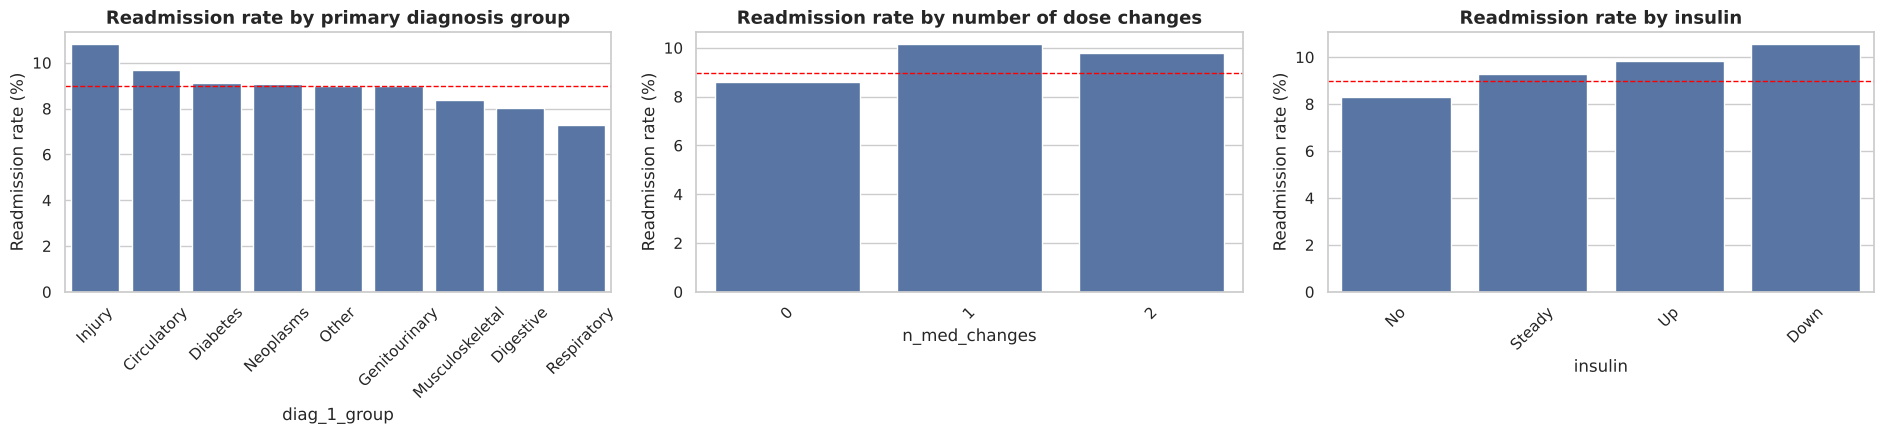

Medication quartile edges: [ 1. 10. 14. 20. 81.]


n  rate_pct
Length of stay      Short (1-3 d)   35144    7.5319
                    Medium (4-7 d)  25075    9.9143
                    Long (8-14 d)    9768   11.7936
Medication quartile Q1              19498    7.2982
                    Q2              16364    8.7081
                    Q3              18682    9.7474
                    Q4              15443   10.4643

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
rate_by("diag_1_group", data=df, ax=axes[0], title="Readmission rate by primary diagnosis group")
rate_by("n_med_changes", data=df, ax=axes[1], order=[0, 1, 2, 3], title="Readmission rate by number of dose changes")
rate_by("insulin", data=df, ax=axes[2], order=["No", "Steady", "Up", "Down"], title="Readmission rate by insulin")
plt.tight_layout(); plt.show()

stay_bins = pd.cut(df["time_in_hospital"], bins=[0, 3, 7, 14], labels=["Short (1-3 d)", "Medium (4-7 d)", "Long (8-14 d)"])
med_q, edges = pd.qcut(df["num_medications"], q=4, labels=["Q1", "Q2", "Q3", "Q4"], retbins=True)
binned = pd.concat([
    df.groupby(stay_bins, observed=True)["readmitted_30d"].agg(n="size", rate_pct=lambda s: 100 * s.mean()),
    df.groupby(med_q, observed=True)["readmitted_30d"].agg(n="size", rate_pct=lambda s: 100 * s.mean()),
], keys=["Length of stay", "Medication quartile"])
print("Medication quartile edges:", edges)
display(binned)

**Reading.**
- **Primary diagnosis group**: moderate differences, from 7.3 % (respiratory) to 10.8 % (injury), circulatory conditions (9.7 %) slightly above average. A secondary factor on its own, but grouping keeps the clinical signal while avoiding ~700 one-hot columns.
- **Dose changes**: 8.6 % without any dose change vs 10.1 % with one and 9.8 % with two — an adjusted (unstable) treatment goes with higher risk (levels with 3+ changes have fewer than 100 patients and are not shown).
- **Insulin**: 8.3 % when not prescribed, 9.3 % steady, 9.8 % increased and 10.5 % decreased.
- **Binned views**: the rate rises with length of stay — 7.5 % (short) → 9.9 % (medium) → 11.8 % (long) — and with the medication quartile, from 7.3 % (Q1, ≤ 10 drugs) to 10.5 % (Q4, > 20). Binning reveals a **gradual** effect that the correlation (≈ 0.05) barely suggested.

### 7.5 Encoding strategy
All remaining categorical features are **nominal** (race, specialty, diagnosis group, discharge…). Integer (label) encoding would invent an order and distances that do not exist, which misleads linear models and KNN. We therefore use **one-hot encoding** with scikit-learn's `OneHotEncoder` *inside the pipeline*: categories are learned on the training set only, unseen categories are handled (`handle_unknown`), and rare levels (< 0.5 % of training rows) are grouped (`min_frequency`). `pd.get_dummies` is avoided for modelling because its columns depend on the levels present in each DataFrame, which can differ between train and test.

### 7.6 Final feature set and leakage control
**Availability rule**: the classifier must be usable **at discharge**, so only information known by then is allowed.

| Variable(s) | Decision | Reason |
|-------------|----------|--------|
| `encounter_id`, `patient_nbr` | excluded | identifiers (memorisation risk) |
| `readmitted` | excluded | raw target → **direct leakage** |
| raw `diag_*`, raw `*_id`, text `age` | replaced | by their grouped / numeric versions |
| rare medications | excluded individually | quasi-constant, summarised by the counts |
| everything else | kept | known at discharge at the latest |

In [22]:
TARGET = "readmitted_30d"
FEATURES_NUM = ["age_num", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
                "n_diabetes_meds", "n_med_changes"]
FEATURES_CAT = ["race", "gender", "admission_type", "admission_source", "discharge", "medical_specialty",
                "diag_1_group", "diag_2_group", "diag_3_group", "max_glu_serum", "A1Cresult",
                "change", "diabetesMed"] + MEDS_KEPT
FEATURES = FEATURES_NUM + FEATURES_CAT
assert "readmitted" not in FEATURES and TARGET not in FEATURES
print(f"{len(FEATURES_NUM)} numeric + {len(FEATURES_CAT)} categorical = {len(FEATURES)} features")
print(f"Modelling dataset: {len(df):,} patients")

11 numeric + 20 categorical = 31 features
Modelling dataset: 69,987 patients


## 8. Classification: predicting 30-day readmission

### 8.1 Train / test split
- **80 % train / 20 % test**, `random_state=42`, **stratified** on the target so both sets have the same readmission rate (≈ 9 %);
- since each patient appears **once** (section 6.2), **no patient is shared** between train and test — checked explicitly.

The test set is held out and used **only for final evaluation**. Every choice (hyperparameters, decision threshold, resampling strategy) is made by **cross-validation on the training set**.

In [23]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

train_patients = set(df.loc[X_train.index, "patient_nbr"])
test_patients = set(df.loc[X_test.index, "patient_nbr"])
assert train_patients.isdisjoint(test_patients), "Leakage: a patient is in both sets!"
print(f"Train: {X_train.shape[0]:,} patients | readmission rate = {y_train.mean():.2%}")
print(f"Test : {X_test.shape[0]:,} patients | readmission rate = {y_test.mean():.2%}")
print("Patients shared by train and test:", len(train_patients & test_patients))

Train: 55,989 patients | readmission rate = 8.98%
Test : 13,998 patients | readmission rate = 8.98%
Patients shared by train and test: 0


### 8.2 Leakage-safe preprocessing pipeline
A `ColumnTransformer` inside a `Pipeline`:
- **numeric**: median imputation → standardisation (needed by logistic regression, KNN and SVM, which are scale-sensitive);
- **categorical**: constant imputation → `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005)`.

`pipeline.fit(X_train, y_train)` learns every statistic on the training data; `predict(X_test)` only applies them. Under cross-validation the whole pipeline is refitted in each fold, so nothing leaks from validation folds.

In [24]:
def make_preprocessor(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005,
                                                sparse_output=False))]), cat),
    ])

preprocessor = make_preprocessor(FEATURES_NUM, FEATURES_CAT)
Xt = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()
print(f"After encoding: {Xt.shape[1]} columns (from {len(FEATURES)} features)")
print("Examples:", list(feature_names[:4]), "...", list(feature_names[-3:]))

After encoding: 123 columns (from 31 features)
Examples: ['num__age_num', 'num__time_in_hospital', 'num__num_lab_procedures', 'num__num_procedures'] ... ['cat__glimepiride_No', 'cat__glimepiride_Steady', 'cat__glimepiride_infrequent_sklearn']


### 8.3 Model comparison

| Model | Idea | Why here | Settings |
|-------|------|----------|----------|
| **Dummy** | always predicts the majority class | mandatory baseline | `most_frequent` |
| **Logistic regression** | sigmoid of a linear combination | standard in clinical risk scores, interpretable (odds ratios) | `class_weight="balanced"` |
| **KNN** | vote of the *k* nearest neighbours | tests "similar patients → similar outcome" | `k=25` |
| **Naive Bayes** | Bayes' rule with independent features | fast probabilistic baseline | `GaussianNB` |
| **Decision tree** | sequence of threshold questions | interpretable, captures interactions | `max_depth=6`, `min_samples_leaf=50`, balanced |
| **SVM (RBF)** | maximum-margin non-linear boundary | strong on small data, but O(n²)–O(n³): trained on a **stratified 8,000-patient subsample** | balanced |
| **Random forest** | average of many bootstrapped trees | robust, lower variance | 300 trees, `min_samples_leaf=20`, balanced |
| **Gradient boosting** (`HistGradientBoosting`) | trees added sequentially to fix residual errors | state of the art on tabular data | balanced |

`class_weight="balanced"` makes each error on a readmitted patient (rare class) cost ≈ 10× more in the loss. Positive class = **readmitted** (`pos_label=1`).

**Metrics**: **recall** = share of readmitted patients detected (business priority); **precision** = share of alerts that are correct; **F1**; **ROC-AUC** (ranking quality, 0.5 = chance); **PR-AUC** (average precision), more demanding under imbalance — its chance level equals the prevalence (≈ 0.09), not 0.5.

In [25]:
def eval_classifier(name, y_true, y_pred, y_proba, seconds=None):
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "recall": recall_score(y_true, y_pred, pos_label=1),
            "F1": f1_score(y_true, y_pred, pos_label=1),
            "ROC-AUC": roc_auc_score(y_true, y_proba),
            "PR-AUC": average_precision_score(y_true, y_proba),
            "% flagged": 100 * y_pred.mean(),
            "fit time (s)": seconds}

models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN (k=25)": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "Naive Bayes": GaussianNB(),
    "Decision tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "SVM RBF (8k)": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
X_svm, _, y_svm, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)

results, pipes, probas, preds = [], {}, {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)), ("model", model)])
    t0 = time.time()
    pipe.fit(X_svm, y_svm) if name.startswith("SVM") else pipe.fit(X_train, y_train)
    secs = time.time() - t0
    pipes[name] = pipe
    preds[name] = pipe.predict(X_test)
    probas[name] = pipe.predict_proba(X_test)[:, 1]
    results.append(eval_classifier(name, y_test, preds[name], probas[name], secs))
    print(f"{name:22s} trained in {secs:6.1f} s")

clf_results = pd.DataFrame(results).set_index("model")
display(clf_results.style.format("{:.3f}").background_gradient(subset=["recall", "F1", "ROC-AUC", "PR-AUC"], cmap="Greens"))

Dummy (majority)       trained in    0.7 s


Logistic regression    trained in    1.6 s


KNN (k=25)             trained in    0.7 s


Naive Bayes            trained in    0.8 s


Decision tree          trained in    0.9 s


SVM RBF (8k)           trained in   24.0 s


Random forest          trained in    9.5 s


Gradient boosting      trained in    1.9 s


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,% flagged,fit time (s)
model,,,,,,,,
Dummy (majority),0.910,0.000,0.000,0.000,0.500,0.090,0.000,0.694
Logistic regression,0.661,0.138,0.528,0.219,0.650,0.170,34.391,1.592
KNN (k=25),0.910,0.000,0.000,0.000,0.577,0.119,0.000,0.662
Naive Bayes,0.385,0.107,0.800,0.189,0.620,0.139,66.902,0.766
Decision tree,0.617,0.128,0.559,0.208,0.629,0.157,39.341,0.948
SVM RBF (8k),0.728,0.138,0.386,0.203,0.605,0.129,25.104,23.989
Random forest,0.809,0.191,0.348,0.247,0.655,0.180,16.381,9.528
Gradient boosting,0.649,0.140,0.564,0.224,0.655,0.184,36.298,1.892


**Reading (test set: 13,998 patients, 1,257 readmitted; default 0.5 threshold).**
- **The accuracy trap**: the `DummyClassifier` has the **best accuracy (0.910)** with a recall of **0** — it never detects a readmission. KNN does exactly the same (no class weighting: the 25-neighbour vote is almost always "not readmitted"). Accuracy is **unusable** here.
- **Ranking quality (ROC-AUC, threshold-free)**: random forest and gradient boosting (0.655) and logistic regression (0.650) lead, ahead of the tree (0.629), Naive Bayes (0.620), the SVM (0.605, handicapped by its 8,000-patient training subsample) and KNN (0.577).
- **PR-AUC** (reference metric for a rare class; chance = 0.090): **gradient boosting first (0.184)**, then random forest (0.176) and logistic regression (0.170) — about **twice chance**.
- **At 0.5**, trade-offs differ: Naive Bayes has the highest recall (0.80) but flags 67 % of patients; random forest is the most conservative (recall 0.33, precision 0.18); gradient boosting (recall 0.56) and logistic regression (0.53) sit in between.

**Conclusion**: performance is **modest** (ROC-AUC ≈ 0.65), in the range usually reported for this dataset. The available variables (administrative, without social, adherence or post-discharge information) capture only part of what drives readmissions. Ensembles bring a real but small gain over a plain logistic regression.

### 8.4 Confusion matrices and ROC / precision-recall curves

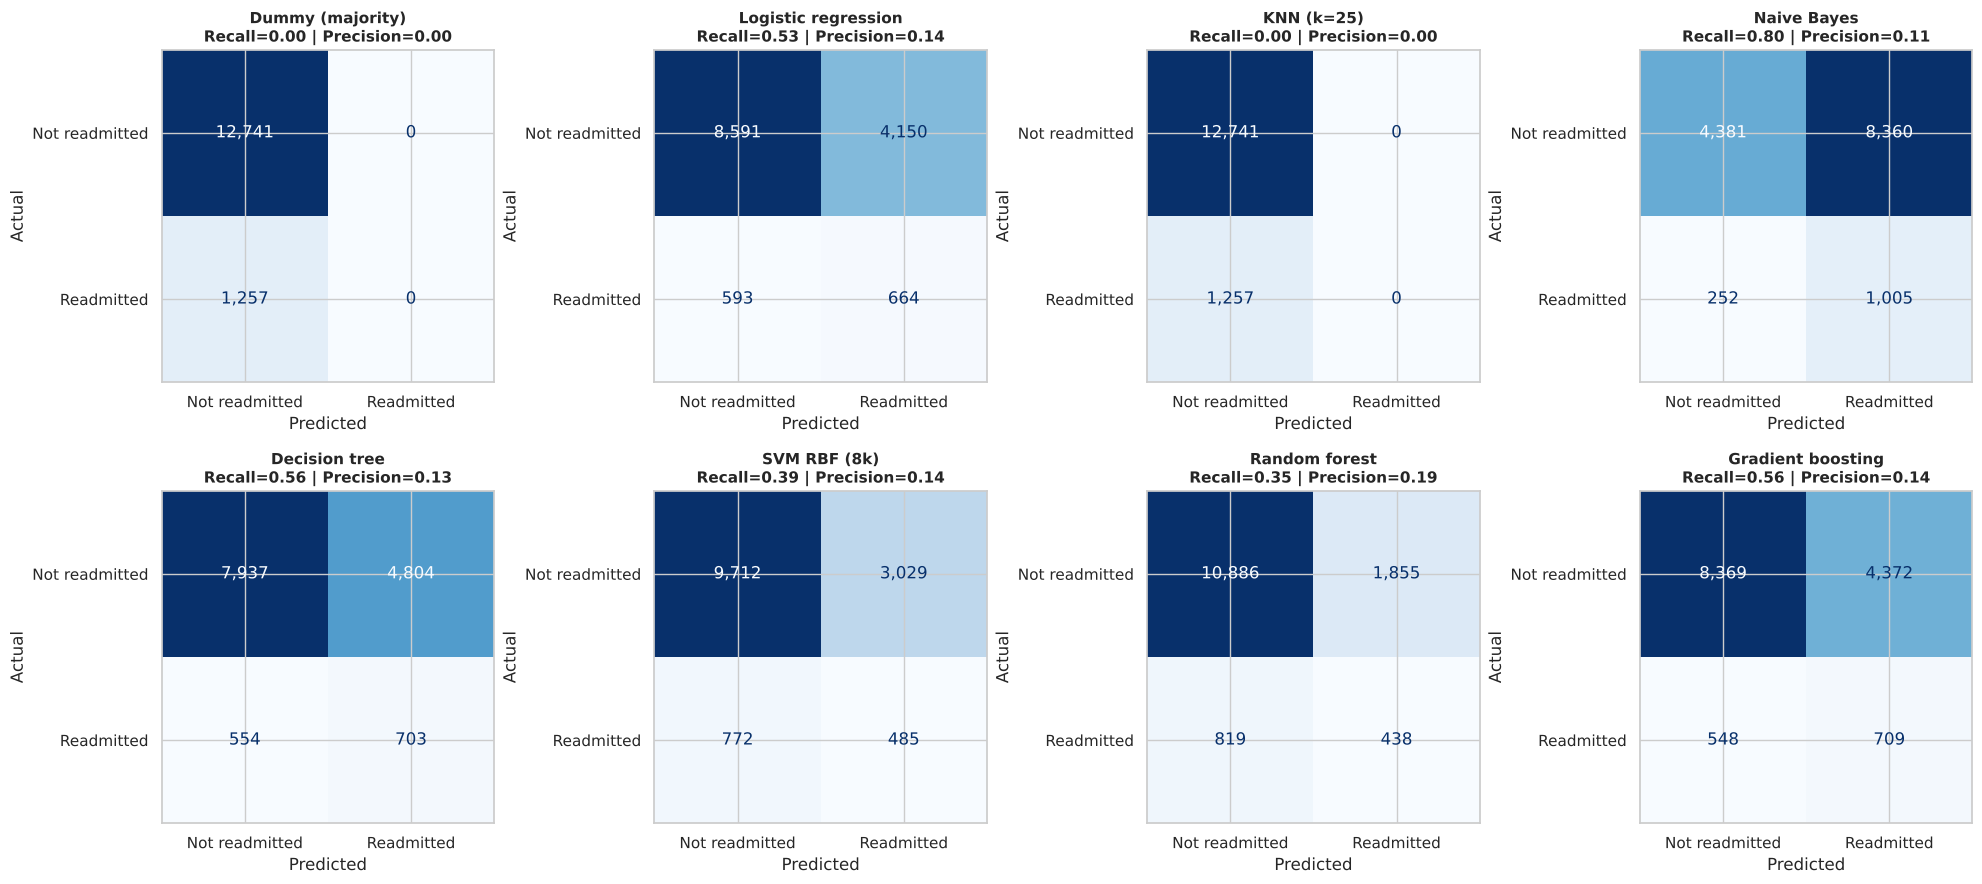

In [26]:
names = list(models)
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), names):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Not readmitted", "Readmitted"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nRecall={tp / (tp + fn):.2f} | Precision={tp / max(tp + fp, 1):.2f}", fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

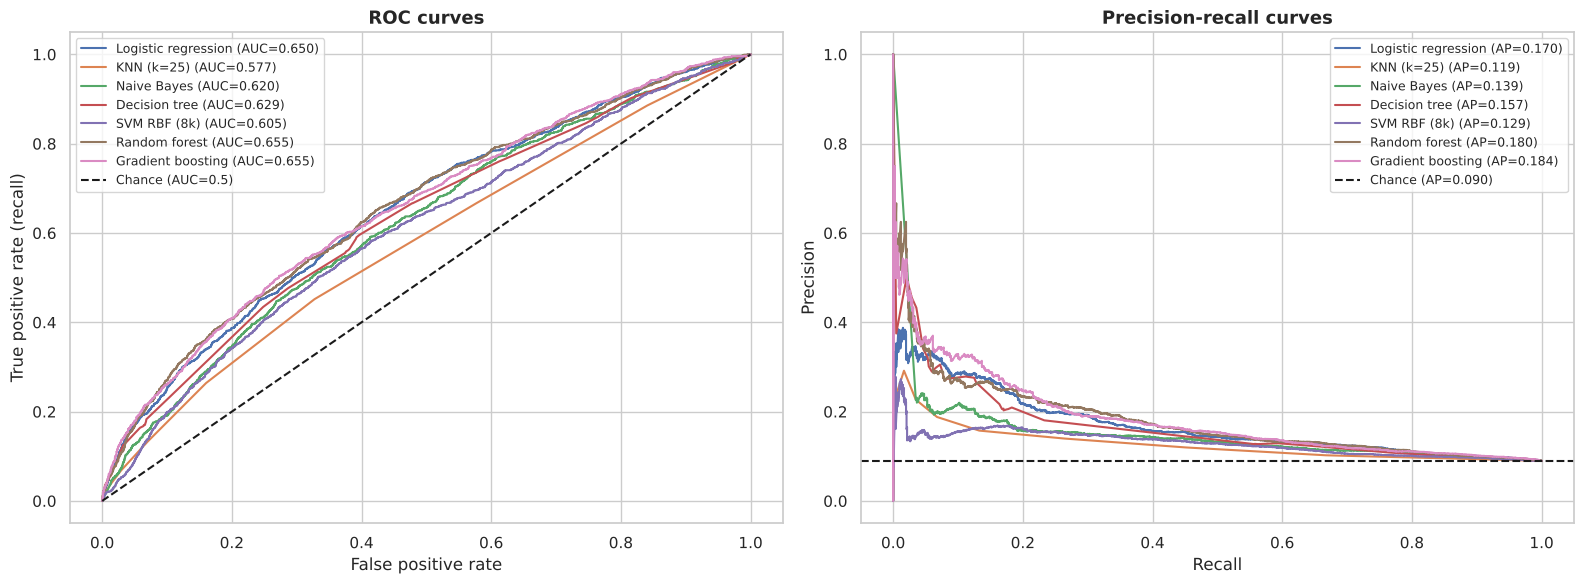

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name in names[1:]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={clf_results.loc[name, 'ROC-AUC']:.3f})")
    p, r, _ = precision_recall_curve(y_test, probas[name])
    axes[1].plot(r, p, label=f"{name} (AP={clf_results.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance (AUC=0.5)")
axes[0].set_title("ROC curves"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Chance (AP={y_test.mean():.3f})")
axes[1].set_title("Precision-recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
for ax in axes: ax.legend(fontsize=9)
plt.tight_layout(); save_fig("roc_pr_curves"); plt.show()

**Reading.**
- Dummy and KNN have an empty "Readmitted" column: they never predict the positive class.
- Logistic regression detects 664 of 1,257 readmissions (recall 0.528) at the cost of 4,150 false alerts (precision 0.138); its specificity is 0.674.
- **ROC**: all curves sit above the diagonal but far from the top-left corner; gradient boosting, random forest and logistic regression almost overlap.
- **Precision-recall**: gradient boosting reaches a precision of about 0.3 only at **very low recall** (< 0.15, the most obvious patients), about 0.2 at a recall of 0.3, and falls towards 0.12–0.15 beyond 50 % recall. This is the real operational cost of detection, which the ROC curve tends to hide under imbalance.

In this context a false positive costs a follow-up call; a false negative is a missed, possibly avoidable readmission — so low precision is acceptable in exchange for good recall.

### 8.5 Handling class imbalance: none vs `class_weight` vs SMOTE
Compared on logistic regression with **5-fold stratified cross-validation on the training set**. SMOTE (*Synthetic Minority Over-sampling Technique*) creates synthetic positives by interpolating between a minority patient and its minority neighbours. It is placed **inside an `imbalanced-learn` pipeline**, so it is applied to the training folds only — never to validation folds or the test set, which must keep the real class distribution.

In [28]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
strategies = {
    "No correction": Pipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)),
                               ("model", LogisticRegression(max_iter=2000))]),
    "class_weight='balanced'": Pipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)),
                                         ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "SMOTE (train folds only)": ImbPipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)),
                                            ("smote", SMOTE(random_state=RANDOM_STATE)),
                                            ("model", LogisticRegression(max_iter=2000))]),
}
rows = {}
for name, p in strategies.items():
    cvres = cross_validate(p, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=-1)
    rows[name] = {k: f"{cvres['test_' + k].mean():.3f} ± {cvres['test_' + k].std():.3f}" for k in scoring}
imbalance = pd.DataFrame(rows).T
imbalance.columns = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
display(imbalance)

,Precision,Recall,F1,ROC-AUC,PR-AUC
No correction,0.459 ± 0.108,0.005 ± 0.001,0.009 ± 0.002,0.640 ± 0.003,0.162 ± 0.004
class_weight='balanced',0.136 ± 0.001,0.527 ± 0.009,0.216 ± 0.002,0.641 ± 0.003,0.162 ± 0.005
SMOTE (train folds only),0.127 ± 0.002,0.528 ± 0.006,0.205 ± 0.002,0.622 ± 0.003,0.153 ± 0.004


**Reading (5-fold CV, mean ± std).**
- **Without correction**, logistic regression has a recall of **0.005**, yet its ROC-AUC (0.640) and PR-AUC (0.162) equal those of the weighted version: the model **ranks** patients just as well — only the 0.5 threshold is inappropriate.
- **`class_weight="balanced"`** raises recall to **0.526** (F1 0.215) without hurting ROC-AUC (0.641) or PR-AUC (0.162).
- **SMOTE** reaches the same recall (0.528) but lower precision, ROC-AUC (0.622) and PR-AUC (0.153). Likely reason: interpolating in one-hot space creates "impossible" synthetic patients (e.g. 0.4 × home + 0.6 × rehabilitation). `SMOTENC`, designed for categorical features, would be more appropriate.

**Decision**: `class_weight="balanced"` — as effective as SMOTE, simpler, faster, no synthetic data. Imbalance is handled as much by **threshold choice** (section 8.8) as by resampling.

### 8.6 Model complexity and hyperparameter tuning
**Overfitting check** — decision-tree depth chosen by cross-validated ROC-AUC (never on the test set). Then **`RandomizedSearchCV`** on gradient boosting (12 random configurations, 3-fold CV, optimising PR-AUC), compared with the default configuration *on the same folds*.

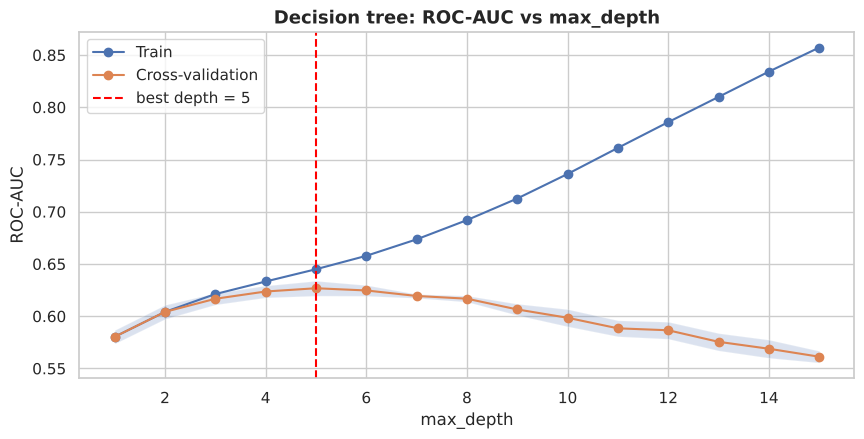

               1      2      3      4      5      6      7      8      9      10     11     12     13     14     15
train      0.5800 0.6040 0.6210 0.6330 0.6450 0.6580 0.6740 0.6920 0.7130 0.7360 0.7610 0.7860 0.8100 0.8340 0.8570
validation 0.5800 0.6040 0.6170 0.6240 0.6270 0.6250 0.6190 0.6170 0.6060 0.5990 0.5880 0.5870 0.5750 0.5690 0.5610


In [29]:
depths = np.arange(1, 16)
tree_pipe = Pipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)),
                      ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))])
tr_sc, va_sc = validation_curve(tree_pipe, X_train, y_train, param_name="model__max_depth",
                                param_range=depths, cv=cv5, scoring="roc_auc", n_jobs=-1)
plt.figure(figsize=(10, 4.5))
plt.plot(depths, tr_sc.mean(1), "o-", label="Train")
plt.plot(depths, va_sc.mean(1), "o-", label="Cross-validation")
plt.fill_between(depths, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2)
best_depth = depths[va_sc.mean(1).argmax()]
plt.axvline(best_depth, color="red", ls="--", label=f"best depth = {best_depth}")
plt.title("Decision tree: ROC-AUC vs max_depth"); plt.xlabel("max_depth"); plt.ylabel("ROC-AUC"); plt.legend(); plt.show()
print(pd.DataFrame({"train": tr_sc.mean(1), "validation": va_sc.mean(1)}, index=depths).round(3).T)

In [30]:
gb_pipe = Pipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)),
                    ("model", HistGradientBoostingClassifier(class_weight="balanced", early_stopping=True,
                                                             random_state=RANDOM_STATE))])
param_dist = {
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [20, 50, 100, 200],
    "model__l2_regularization": [0.0, 0.1, 1.0, 5.0],
    "model__max_iter": [200, 400],
}
cv3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
t0 = time.time()
search = RandomizedSearchCV(gb_pipe, param_dist, n_iter=12, scoring="average_precision", cv=cv3,
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True)
search.fit(X_train, y_train)
cv_default = cross_val_score(gb_pipe, X_train, y_train, cv=cv3, scoring="average_precision", n_jobs=-1)
print(f"Search done in {time.time() - t0:.0f} s")
print(f"CV PR-AUC — default: {cv_default.mean():.4f} ± {cv_default.std():.4f} | tuned: {search.best_score_:.4f}")
print("Best hyperparameters:", {k.replace('model__', ''): v for k, v in search.best_params_.items()})

if search.best_score_ >= cv_default.mean():          # model selection on CV only
    best_model, FINAL_NAME = search.best_estimator_, "Gradient boosting (tuned)"
else:
    best_model, FINAL_NAME = clone(gb_pipe).fit(X_train, y_train), "Gradient boosting (default)"
print("Final model:", FINAL_NAME)

proba_best = best_model.predict_proba(X_test)[:, 1]
pred_best = best_model.predict(X_test)
clf_results.loc["Gradient boosting (tuned)"] = eval_classifier("Gradient boosting (tuned)", y_test,
    search.best_estimator_.predict(X_test), search.best_estimator_.predict_proba(X_test)[:, 1])
display(clf_results.loc[["Logistic regression", "Random forest", "Gradient boosting", "Gradient boosting (tuned)"]]
        .drop(columns="fit time (s)").style.format("{:.3f}"))

Search done in 64 s
CV PR-AUC — default: 0.1664 ± 0.0046 | tuned: 0.1681
Best hyperparameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 200, 'max_depth': 5, 'learning_rate': 0.1, 'l2_regularization': 1.0}
Final model: Gradient boosting (tuned)


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,% flagged
model,,,,,,,
Logistic regression,0.661,0.138,0.528,0.219,0.650,0.170,34.391
Random forest,0.809,0.191,0.348,0.247,0.655,0.180,16.381
Gradient boosting,0.649,0.140,0.564,0.224,0.655,0.184,36.298
Gradient boosting (tuned),0.650,0.139,0.556,0.222,0.653,0.179,36.019


**Reading.**
- **Tree depth**: training ROC-AUC keeps rising with depth (0.58 → 0.86) as the tree memorises the training data, while cross-validated ROC-AUC peaks at **0.627 for depth 5** and then declines (0.561 at depth 15) — classic **overfitting**, visible as the widening gap between the curves.
- **Gradient boosting**: the best configuration (`learning_rate=0.1`, `max_depth=5`, `max_leaf_nodes=31`, `min_samples_leaf=20`, `l2_regularization=1.0`, 200 iterations) reaches a CV PR-AUC of **0.168** vs **0.166 ± 0.005** for the defaults on the same folds — a gain **smaller than the fold-to-fold standard deviation**. On the test set the tuned model is even marginally below the default (0.179 vs 0.184 PR-AUC); choosing on the test set would itself be leakage, and differences of this size are sampling noise.

**Takeaway**: when hyperparameters barely matter, **the bottleneck is the information in the data, not the model**. Further gains require new features, not finer tuning.

### 8.7 Experiment: how much does patient-level leakage inflate the results?
Section 6.2 argued that keeping several encounters per patient leaks information. Here we **measure** it. On the **encounter-level** dataset (all encounters, same cleaning otherwise), we train the same gradient-boosting pipeline twice:
- **(a) naive random split** of encounters (what a quick analysis would do) — the same patient can appear in train and test;
- **(b) patient-grouped split** (`GroupShuffleSplit` on `patient_nbr`) — every patient is entirely in train or entirely in test.

Both use the same features, model and 80/20 proportions. Any gap between (a) and (b) is optimism caused by leakage.

In [31]:
df_enc = engineer_features(raw.pipe(clean_data, first_encounter_only=False))
X_enc, y_enc, groups = df_enc[FEATURES], df_enc[TARGET], df_enc["patient_nbr"]
print(f"Encounter-level dataset: {len(df_enc):,} encounters, {groups.nunique():,} patients, "
      f"readmission rate {y_enc.mean():.2%}")

splits = {"(a) naive random split": train_test_split(np.arange(len(df_enc)), test_size=0.2, stratify=y_enc,
                                                     random_state=RANDOM_STATE),
          "(b) patient-grouped split": next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                                                              random_state=RANDOM_STATE).split(X_enc, y_enc, groups))}
leak_rows = []
for name, (tr, te) in splits.items():
    m = clone(gb_pipe).fit(X_enc.iloc[tr], y_enc.iloc[tr])
    p = m.predict_proba(X_enc.iloc[te])[:, 1]
    shared = groups.iloc[te].isin(set(groups.iloc[tr])).mean()
    leak_rows.append({"split": name, "test encounters": len(te), "test prevalence": y_enc.iloc[te].mean(),
                      "% test encounters whose patient is in train": 100 * shared,
                      "ROC-AUC": roc_auc_score(y_enc.iloc[te], p), "PR-AUC": average_precision_score(y_enc.iloc[te], p),
                      "PR-AUC / prevalence": average_precision_score(y_enc.iloc[te], p) / y_enc.iloc[te].mean()})
leakage = pd.DataFrame(leak_rows).set_index("split")
display(leakage.style.format("{:.3f}", subset=["test prevalence", "ROC-AUC", "PR-AUC", "PR-AUC / prevalence"])
        .format("{:.1f}", subset=["% test encounters whose patient is in train"]))

Encounter-level dataset: 99,340 encounters, 69,987 patients, readmission rate 11.39%


,test encounters,test prevalence,% test encounters whose patient is in train,ROC-AUC,PR-AUC,PR-AUC / prevalence
split,,,,,,
(a) naive random split,19868,0.114,41.6,0.671,0.229,2.013
(b) patient-grouped split,19773,0.113,0.0,0.675,0.237,2.084


**Reading.** With the naive split, **41.6 %** of test encounters belong to a patient also present in training; with the grouped split, none. Yet the scores are **essentially identical** — ROC-AUC 0.671 vs 0.675, PR-AUC 0.229 vs 0.237, lift over prevalence 2.01 vs 2.08 — and the small differences go in the "wrong" direction, well within the sampling noise measured in section 8.10.

**What this means.**
- In this setting, encounter-level leakage does **not** measurably inflate performance: without an identifier feature, gradient boosting cannot exploit "this is the same patient". We report this honestly rather than assuming it.
- The bigger effect is a **population shift**: the encounter-level dataset contains repeat encounters of frequently admitted patients, so prevalence (11.4 % vs 9.0 %) and scores (PR-AUC 0.23 vs 0.18) are higher than for the real use case — a first discharge. Evaluating on all encounters would make the model look better than it is for that use case.
- The patient-level design costs nothing and removes the risk, so it remains the right default.

### 8.8 Decision threshold: trading recall against alert volume
By default `predict()` flags a patient when the probability exceeds 0.5 — a threshold with no clinical meaning. The model provides a **risk score**; the operating threshold is a hospital decision.

Procedure: (1) out-of-fold probabilities on the training set (`cross_val_predict`), (2) pick the threshold maximising **F2** (recall weighted twice as much as precision, matching the business priority), (3) apply it **once** to the test set. A **capacity-based** alternative (the hospital can follow up 20 % of discharged patients) is reported too.

F2-optimal threshold (out-of-fold, train): 0.43 | 20 % capacity threshold: 0.559


,threshold,% flagged,recall,precision,specificity,readmissions caught,readmissions missed,false alerts
operating point,,,,,,,,
Max F2 (recall first),0.4300,57.3010,0.7420,0.1160,0.4440,933,324,7088
Default 0.5,0.5000,36.0190,0.5560,0.1390,0.6590,699,558,4343
Capacity 20 %,0.5590,19.5460,0.3750,0.1730,0.8220,472,785,2264


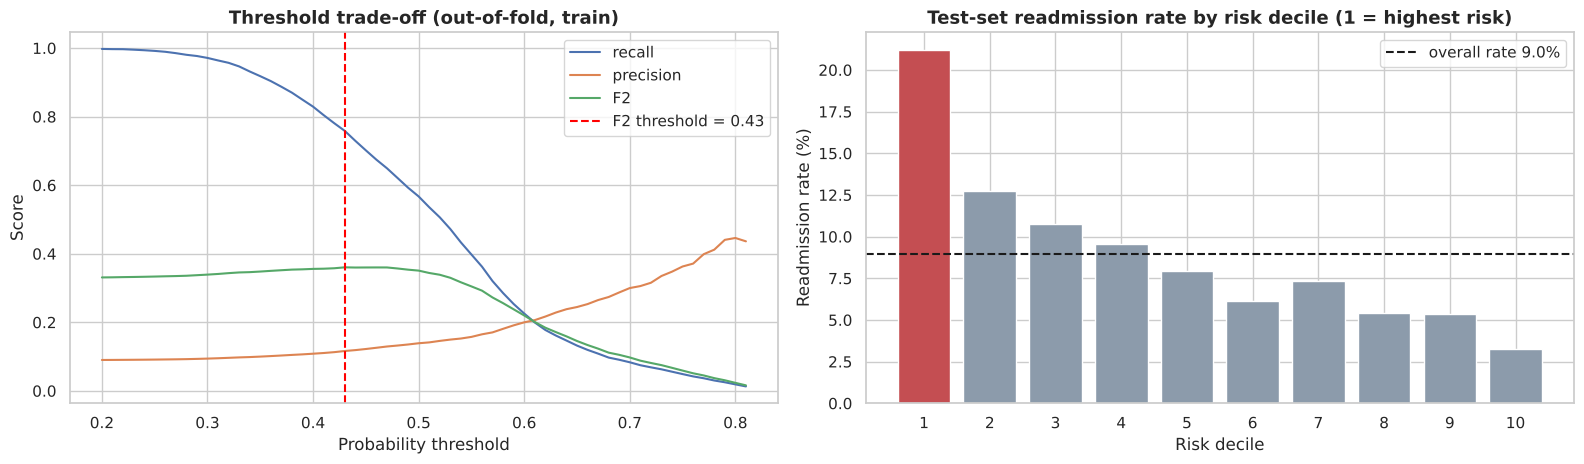

,patients,readmission rate,lift,cumulative % of readmissions captured
decile,,,,
1,1400,21.2%,2.36,23.6
2,1400,12.7%,1.42,37.8
3,1400,10.8%,1.20,49.8
4,1399,9.6%,1.07,60.5
5,1400,7.9%,0.88,69.3
6,1400,6.1%,0.68,76.1
7,1399,7.4%,0.82,84.3
8,1400,5.4%,0.60,90.4
9,1400,5.4%,0.60,96.3


In [32]:
proba_oof = cross_val_predict(best_model, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                              method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
thr_table = pd.DataFrame({
    "threshold": thresholds,
    "recall": [recall_score(y_train, proba_oof >= t) for t in thresholds],
    "precision": [precision_score(y_train, proba_oof >= t, zero_division=0) for t in thresholds],
    "F2": [fbeta_score(y_train, proba_oof >= t, beta=2) for t in thresholds],
    "% flagged": [100 * (proba_oof >= t).mean() for t in thresholds],
})
THRESHOLD = float(thr_table.loc[thr_table["F2"].idxmax(), "threshold"])
THRESHOLD_CAPACITY = float(np.quantile(proba_oof, 0.80))
print(f"F2-optimal threshold (out-of-fold, train): {THRESHOLD:.2f} | 20 % capacity threshold: {THRESHOLD_CAPACITY:.3f}")

points = []
for name, t in [("Max F2 (recall first)", THRESHOLD), ("Default 0.5", 0.5), ("Capacity 20 %", THRESHOLD_CAPACITY)]:
    pr = (proba_best >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pr).ravel()
    points.append({"operating point": name, "threshold": t, "% flagged": 100 * pr.mean(), "recall": tp_ / (tp_ + fn_),
                   "precision": tp_ / (tp_ + fp_), "specificity": tn_ / (tn_ + fp_),
                   "readmissions caught": tp_, "readmissions missed": fn_, "false alerts": fp_})
display(pd.DataFrame(points).set_index("operating point").round(3))

pred_thr = (proba_best >= THRESHOLD).astype(int)
deciles = 10 - pd.qcut(pd.Series(proba_best).rank(method="first"), 10, labels=False)   # 1 = highest risk
lift = pd.DataFrame({"decile": deciles.values, "y": y_test.values}).groupby("decile")["y"].agg(["size", "mean"])
lift.columns = ["patients", "readmission rate"]
lift["lift"] = lift["readmission rate"] / y_test.mean()
lift["cumulative % of readmissions captured"] = 100 * (lift["readmission rate"] * lift["patients"]).cumsum() / y_test.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for c in ["recall", "precision", "F2"]:
    axes[0].plot(thr_table["threshold"], thr_table[c], label=c)
axes[0].axvline(THRESHOLD, color="red", ls="--", label=f"F2 threshold = {THRESHOLD:.2f}")
axes[0].set_title("Threshold trade-off (out-of-fold, train)"); axes[0].set_xlabel("Probability threshold"); axes[0].set_ylabel("Score"); axes[0].legend()
axes[1].bar(lift.index.astype(str), lift["readmission rate"] * 100, color=["#C44E52"] + ["#8C9BAB"] * 9)
axes[1].axhline(y_test.mean() * 100, color="k", ls="--", label=f"overall rate {y_test.mean():.1%}")
axes[1].set_title("Test-set readmission rate by risk decile (1 = highest risk)"); axes[1].set_xlabel("Risk decile"); axes[1].set_ylabel("Readmission rate (%)"); axes[1].legend()
plt.tight_layout(); save_fig("threshold_and_lift"); plt.show()
display(lift.style.format({"readmission rate": "{:.1%}", "lift": "{:.2f}", "cumulative % of readmissions captured": "{:.1f}"}))

**Reading.**
- Out-of-fold F2 is maximal at **0.43**. Applied **once** to the test set it gives a **recall of 0.742** (933 of 1,257 readmissions caught, 324 missed), precision 0.116 and **57 % of patients flagged** — very close to what the training set predicted (recall 0.759, 58.6 % flagged): the threshold **generalises**.
- **Operational limit**: flagging 57 % of patients is close to following everyone. The **capacity-based** point (threshold 0.559) flags 19.5 % of patients, catches **37.5 %** of readmissions with precision **0.173** (about twice the base rate) and produces 2,264 false alerts instead of 7,088.
- **Risk deciles**: the top 10 % of patients have a readmission rate of **21.2 %**, i.e. **2.36×** the average (9.0 %), and contain 23.6 % of all readmissions; the top 30 % contain 49.8 %. The lowest decile has only 3.3 %.

**Recommendation**: the threshold is a **clinical-economic decision**, not a statistical one. The model is best used as a **prioritisation tool**: rank patients by risk and follow up from the top down, as far as resources allow.

### 8.9 Calibration: can the probabilities be trusted?
Ranking patients well (discrimination) is not enough: a predicted risk of 30 % should mean that about 30 % of such patients are readmitted. `class_weight="balanced"` deliberately **distorts** probabilities (it pretends positives are as frequent as negatives), so we expect over-estimation.

We plot a **reliability diagram**, compute the **Brier score** (mean squared error of probabilities; lower is better), and recalibrate with **isotonic regression** (`CalibratedClassifierCV`, 5-fold, fitted on the training set only). Isotonic calibration is monotonic, so it keeps the ranking (ROC-AUC) essentially unchanged.

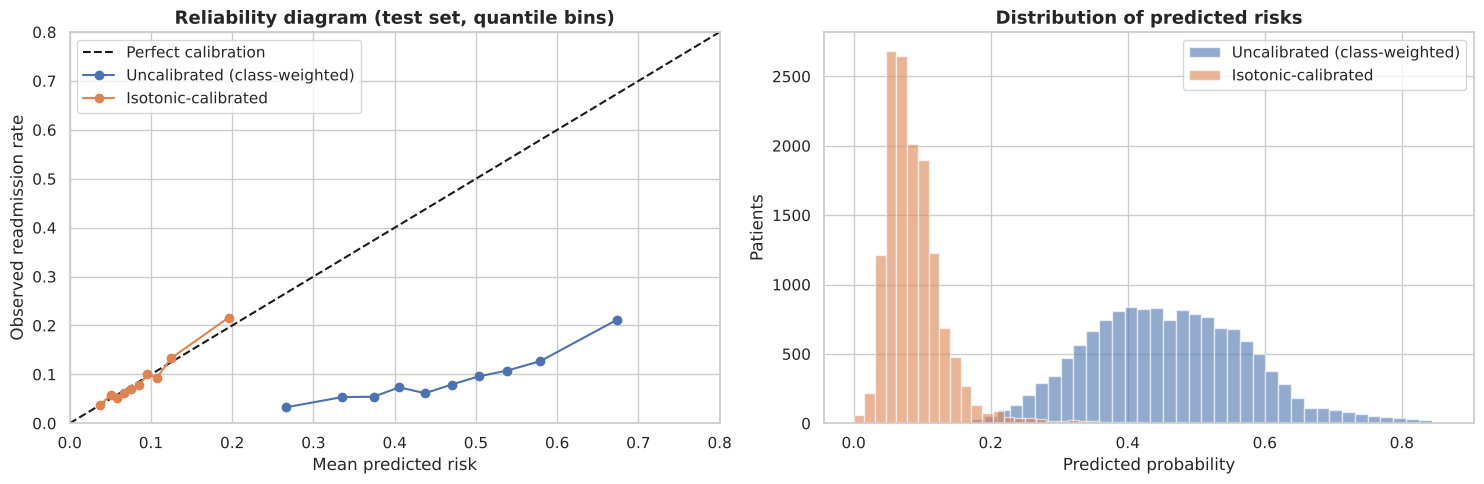

,Brier score,mean predicted risk,observed rate,ROC-AUC,PR-AUC
model,,,,,
Uncalibrated (class-weighted),0.2202,0.4585,0.0898,0.6535,0.1791
Isotonic-calibrated,0.0787,0.0895,0.0898,0.6544,0.1845


Reference Brier score (predict the training prevalence for everyone): 0.0817


In [33]:
calibrated = CalibratedClassifierCV(clone(best_model), method="isotonic", cv=5)
calibrated.fit(X_train, y_train)
proba_cal = calibrated.predict_proba(X_test)[:, 1]

cal_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for name, p in [("Uncalibrated (class-weighted)", proba_best), ("Isotonic-calibrated", proba_cal)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, "o-", label=name)
    axes[1].hist(p, bins=40, alpha=0.6, label=name)
    cal_rows.append({"model": name, "Brier score": brier_score_loss(y_test, p), "mean predicted risk": p.mean(),
                     "observed rate": y_test.mean(), "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})
axes[0].set_xlim(0, 0.8); axes[0].set_ylim(0, 0.8)
axes[0].set_title("Reliability diagram (test set, quantile bins)"); axes[0].set_xlabel("Mean predicted risk"); axes[0].set_ylabel("Observed readmission rate"); axes[0].legend()
axes[1].set_title("Distribution of predicted risks"); axes[1].set_xlabel("Predicted probability"); axes[1].set_ylabel("Patients"); axes[1].legend()
plt.tight_layout(); save_fig("calibration"); plt.show()
brier_ref = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
display(pd.DataFrame(cal_rows).set_index("model").round(4))
print(f"Reference Brier score (predict the training prevalence for everyone): {brier_ref:.4f}")

**Reading.**
- **Uncalibrated scores are badly over-estimated**: the class-weighted model predicts a mean risk of **45.9 %** for an observed rate of **9.0 %**; every reliability point lies far below the diagonal. Its Brier score (0.220) is even **worse** than predicting the base rate for everyone (0.0817). These scores are fine for **ranking** but must never be read as probabilities.
- **After isotonic calibration** the points follow the diagonal, the mean predicted risk is **8.95 %** and the Brier score drops to **0.0787**, below the 0.0817 reference. ROC-AUC is unchanged (0.654) since calibration preserves the ranking.
- Calibrated risks are concentrated between 3 % and 20 %: the model separates "low" from "moderately high" risk; it does not identify near-certain readmissions.

**Practical rule**: use the raw score (or its rank) to choose whom to follow up, and the **calibrated** probability whenever a risk is communicated or used in a cost-benefit calculation.

### 8.10 Uncertainty: bootstrap confidence intervals on the test set
A single test score hides sampling noise. We resample the test set with replacement 1,000 times and report **95 % percentile intervals**.

In [34]:
rng = np.random.RandomState(RANDOM_STATE)
yt, pb, pc = y_test.values, proba_best, proba_cal
boot = {"ROC-AUC": [], "PR-AUC": [], f"Recall @ {THRESHOLD:.2f}": [], f"Precision @ {THRESHOLD:.2f}": [], "Brier (calibrated)": []}
for _ in range(1000):
    i = rng.randint(0, len(yt), len(yt))
    yb, pbb = yt[i], pb[i]
    boot["ROC-AUC"].append(roc_auc_score(yb, pbb))
    boot["PR-AUC"].append(average_precision_score(yb, pbb))
    boot[f"Recall @ {THRESHOLD:.2f}"].append(recall_score(yb, pbb >= THRESHOLD))
    boot[f"Precision @ {THRESHOLD:.2f}"].append(precision_score(yb, pbb >= THRESHOLD))
    boot["Brier (calibrated)"].append(brier_score_loss(yb, pc[i]))
point = {"ROC-AUC": roc_auc_score(yt, pb), "PR-AUC": average_precision_score(yt, pb),
         f"Recall @ {THRESHOLD:.2f}": recall_score(yt, pb >= THRESHOLD),
         f"Precision @ {THRESHOLD:.2f}": precision_score(yt, pb >= THRESHOLD), "Brier (calibrated)": brier_score_loss(yt, pc)}
ci = pd.DataFrame({"estimate": point, "95% CI low": {k: np.percentile(v, 2.5) for k, v in boot.items()},
                   "95% CI high": {k: np.percentile(v, 97.5) for k, v in boot.items()}})
display(ci.round(3))

,estimate,95% CI low,95% CI high
ROC-AUC,0.6530,0.6380,0.6700
PR-AUC,0.1790,0.1630,0.1990
Recall @ 0.43,0.7420,0.7180,0.7670
Precision @ 0.43,0.1160,0.1100,0.1240
Brier (calibrated),0.0790,0.0750,0.0820


**Reading.** ROC-AUC **0.653 [0.638–0.670]**, PR-AUC **0.179 [0.163–0.199]**, recall at 0.43 **0.742 [0.718–0.767]**, precision **0.116 [0.110–0.124]**, calibrated Brier **0.079 [0.075–0.082]**. The PR-AUC interval stays far above the 0.090 chance level, so the model's value is not a sampling accident. The intervals also put earlier comparisons in perspective: differences of ±0.005 in PR-AUC between gradient-boosting variants (section 8.6) are well inside this uncertainty.

### 8.11 Clinical usefulness: decision curve analysis
Decision curve analysis (Vickers & Elkin, 2006) asks whether acting on the model **does more good than harm** compared with "follow up everyone" or "follow up no one". For a threshold probability *pₜ* (the risk at which a clinician would intervene), the **net benefit** is

$$\text{NB}(p_t) = \frac{TP}{n} - \frac{FP}{n}\cdot\frac{p_t}{1-p_t}$$

A false alert is weighted by the odds *pₜ/(1−pₜ)*: at *pₜ* = 10 %, one true detection is judged worth nine unnecessary follow-ups. Calibrated probabilities are required, so the isotonic-calibrated model is used.

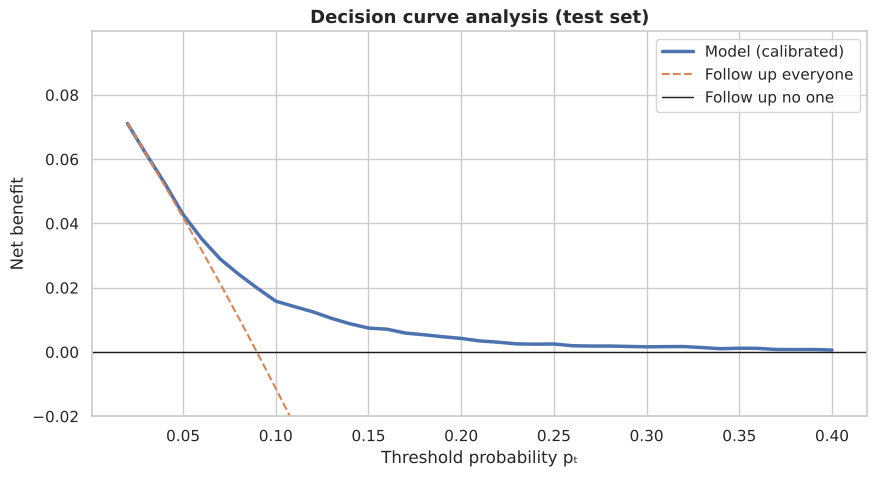

Model adds net benefit over both default strategies for thresholds from 0.03 to 0.40


,model,treat all,model better than both
threshold,,,
0.0500,0.0428,0.0419,True
0.0800,0.0242,0.0107,True
0.1000,0.0158,-0.0113,True
0.1500,0.0075,-0.0708,True
0.2000,0.0042,-0.1378,True
0.2500,0.0025,-0.2136,True
0.3000,0.0016,-0.3003,True


In [35]:
pts = np.round(np.arange(0.02, 0.41, 0.01), 2)
n, prev = len(y_test), y_test.mean()
def net_benefit(p, pt):
    pred = p >= pt
    tp = np.sum(pred & (yt == 1)); fp = np.sum(pred & (yt == 0))
    return tp / n - fp / n * pt / (1 - pt)
nb_model = [net_benefit(proba_cal, t) for t in pts]
nb_all = [prev - (1 - prev) * t / (1 - t) for t in pts]
plt.figure(figsize=(10, 5))
plt.plot(pts, nb_model, lw=2.5, label="Model (calibrated)")
plt.plot(pts, nb_all, ls="--", label="Follow up everyone")
plt.axhline(0, color="k", lw=1, label="Follow up no one")
plt.ylim(-0.02, prev + 0.01); plt.xlabel("Threshold probability pₜ"); plt.ylabel("Net benefit")
plt.title("Decision curve analysis (test set)"); plt.legend(); save_fig("decision_curve"); plt.show()
dca = pd.DataFrame({"threshold": pts, "model": nb_model, "treat all": nb_all})
dca["model better than both"] = (dca["model"] > dca["treat all"]) & (dca["model"] > 0)
useful = dca.loc[dca["model better than both"], "threshold"]
print(f"Model adds net benefit over both default strategies for thresholds from {useful.min():.2f} to {useful.max():.2f}")
display(dca[dca["threshold"].isin([0.05, 0.08, 0.10, 0.15, 0.20, 0.25, 0.30])].set_index("threshold").round(4))

**Reading.** The model's net benefit is above both "follow up everyone" and "follow up no one" for every threshold probability from **3 % to 40 %**. Around the base rate (5–10 %), where a hospital would typically act for a cheap intervention such as a phone call, the advantage is clearest: at *pₜ* = 10 % the model yields a net benefit of **0.016** (equivalent to correctly targeting 1.6 readmissions per 100 patients with no unnecessary follow-up), while following everyone is already harmful (−0.011). Above ~20 % the benefit stays positive but becomes small, because few patients reach such calibrated risks. The model is therefore **clinically useful for low-cost, broad interventions**, less so for expensive targeted ones.

### 8.12 Explainability
Three complementary views:
1. **Permutation importance** on the test set (drop in PR-AUC when a feature is shuffled) — model-agnostic and computed on the original features;
2. **SHAP values** (Lundberg & Lee, 2017) for the gradient-boosting model — how each feature pushes each patient's risk up or down, globally and for one patient;
3. **Logistic-regression odds ratios** and a **shallow decision tree** — simple, transparent cross-checks.

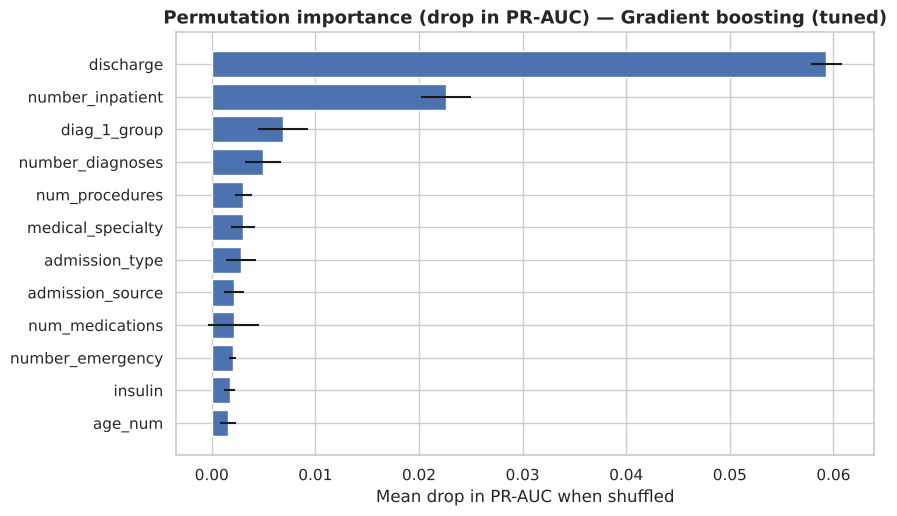

,importance,std
discharge,0.0593,0.0015
number_inpatient,0.0226,0.0024
diag_1_group,0.0069,0.0024
number_diagnoses,0.0049,0.0017
num_procedures,0.0031,0.0008
medical_specialty,0.0030,0.0012
admission_type,0.0028,0.0015
admission_source,0.0022,0.0009
num_medications,0.0021,0.0025
number_emergency,0.0020,0.0003


In [36]:
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": perm.importances_mean, "std": perm.importances_std},
                   index=X_test.columns).sort_values("importance", ascending=False)
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(9, 5.5))
plt.barh(top.index, top["importance"], xerr=top["std"], color="#4C72B0")
plt.title(f"Permutation importance (drop in PR-AUC) — {FINAL_NAME}"); plt.xlabel("Mean drop in PR-AUC when shuffled")
save_fig("permutation_importance"); plt.show()
display(imp.head(10).round(4))

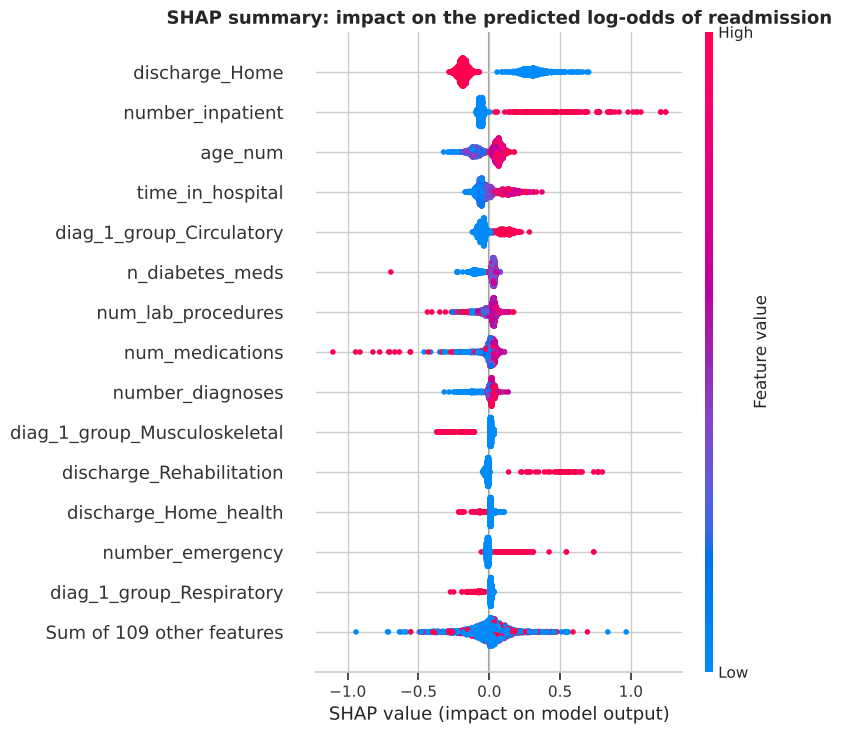

Mean |SHAP| (top 10):
discharge_Home                 0.2288
number_inpatient               0.0989
age_num                        0.0776
time_in_hospital               0.0716
diag_1_group_Circulatory       0.0702
n_diabetes_meds                0.0452
num_lab_procedures             0.0406
num_medications                0.0364
number_diagnoses               0.0308
diag_1_group_Musculoskeletal   0.0254
dtype: float64


In [37]:
prep_fitted, gb_fitted = best_model.named_steps["prep"], best_model.named_steps["model"]
shap_names = [n.replace("num__", "").replace("cat__", "") for n in prep_fitted.get_feature_names_out()]
X_shap = pd.DataFrame(prep_fitted.transform(X_test.sample(2000, random_state=RANDOM_STATE)), columns=shap_names)
explainer = shap.TreeExplainer(gb_fitted)
sv = explainer(X_shap)
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP summary: impact on the predicted log-odds of readmission"); plt.tight_layout()
save_fig("shap_summary"); plt.show()

mean_abs = pd.Series(np.abs(sv.values).mean(0), index=shap_names).sort_values(ascending=False)
print("Mean |SHAP| (top 10):"); print(mean_abs.head(10).round(4))

Patient #1285: predicted (uncalibrated) risk = 0.853


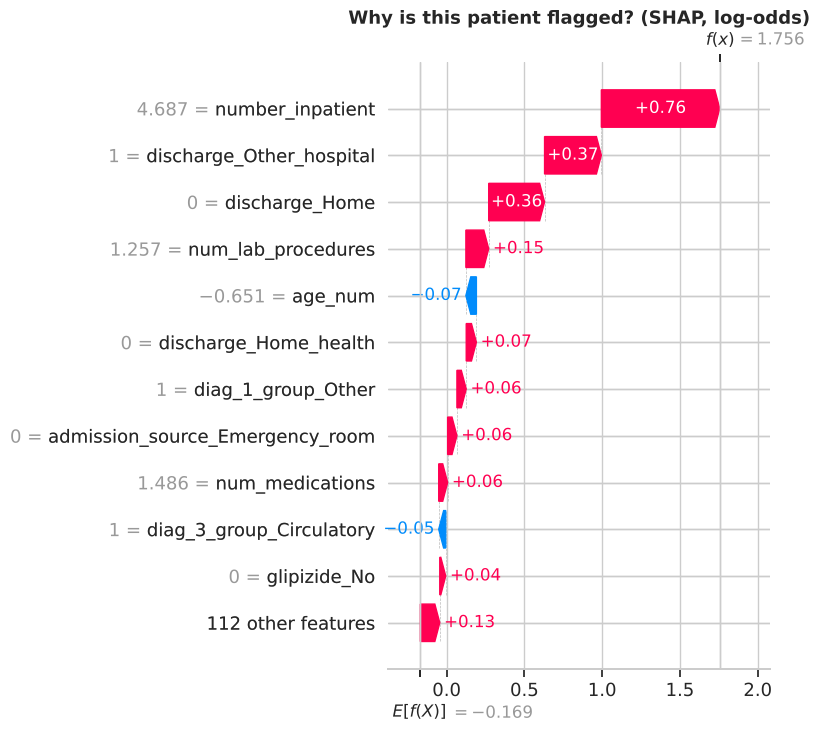

In [38]:
# Local explanation: the highest-risk patient of the sample
idx = int(np.argmax(gb_fitted.predict_proba(X_shap.values)[:, 1]))
print(f"Patient #{idx}: predicted (uncalibrated) risk = {gb_fitted.predict_proba(X_shap.values[[idx]])[0, 1]:.3f}")
plt.figure()
shap.plots.waterfall(sv[idx], max_display=12, show=False)
plt.title("Why is this patient flagged? (SHAP, log-odds)"); plt.tight_layout(); plt.show()

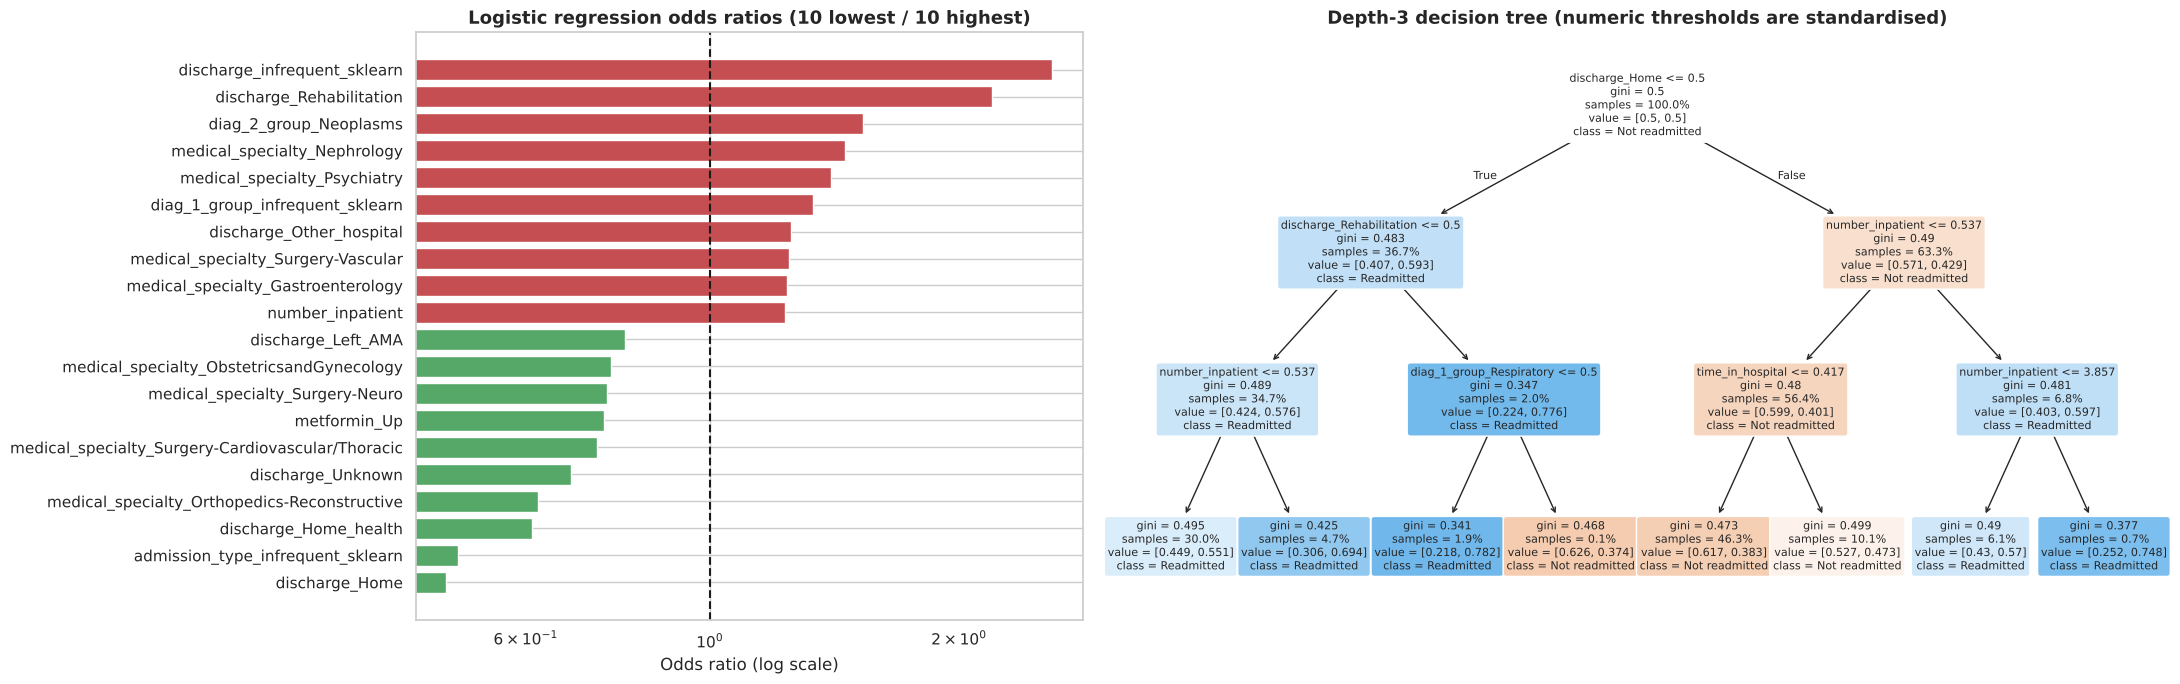

number_inpatient: 0 visits -> z = -0.29 | 1 visit -> z = 1.37 | 3 visits -> z = 4.69


In [39]:
lr = pipes["Logistic regression"]
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
odds = np.exp(coefs).sort_values()
sel = pd.concat([odds.head(10), odds.tail(10)])
fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh([s.replace("num__", "").replace("cat__", "") for s in sel.index], sel.values,
             color=["#55A868" if v < 1 else "#C44E52" for v in sel.values])
axes[0].axvline(1, color="k", ls="--"); axes[0].set_xscale("log")
axes[0].set_title("Logistic regression odds ratios (10 lowest / 10 highest)"); axes[0].set_xlabel("Odds ratio (log scale)")
tree_vis = Pipeline([("prep", make_preprocessor(FEATURES_NUM, FEATURES_CAT)),
                     ("model", DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train, y_train)
plot_tree(tree_vis.named_steps["model"], ax=axes[1], fontsize=8, filled=True, rounded=True, proportion=True,
          feature_names=[n.replace("num__", "").replace("cat__", "") for n in tree_vis.named_steps["prep"].get_feature_names_out()],
          class_names=["Not readmitted", "Readmitted"])
axes[1].set_title("Depth-3 decision tree (numeric thresholds are standardised)")
plt.tight_layout(); plt.show()
sc = tree_vis.named_steps["prep"].named_transformers_["num"].named_steps["scaler"]
j = FEATURES_NUM.index("number_inpatient")
print(f"number_inpatient: 0 visits -> z = {(0 - sc.mean_[j]) / sc.scale_[j]:.2f} | 1 visit -> z = {(1 - sc.mean_[j]) / sc.scale_[j]:.2f} "
      f"| 3 visits -> z = {(3 - sc.mean_[j]) / sc.scale_[j]:.2f}")

**Reading — the three views agree.**
1. **Discharge disposition** dominates: permutation drop of 0.059 PR-AUC (more than twice the next), top SHAP feature (`discharge_Home`: being discharged home pushes risk **down**, any other destination pushes it up), root of the decision tree, and lowest odds ratio for home discharge. Rehabilitation and transfer to another hospital raise risk. Not going home is a **marker of frailty**.
2. **Prior-year inpatient visits** come second (0.023; second SHAP feature, with a long tail of large positive contributions). In the tree, the 0.537 split separates **0** from **≥ 1** visit (z = −0.29 vs 1.37) and the 3.857 split isolates patients with **3 or more** prior admissions (z = 4.69 for 3), the most "readmitted" leaf of the home-discharge branch.
3. **Secondary factors**: age, length of stay, primary diagnosis group (circulatory ↑, musculoskeletal and respiratory ↓), number of diagnoses, specialty (nephrology, psychiatry ↑), admission type and source.
4. **Little value** from HbA1c, glucose and individual drugs: the **care pathway** predicts readmission better than **diabetes biomarkers**.

**Local explanation**: the highest-risk patient of the sample (score 0.85) is driven mainly by a heavy admission history (+0.76 log-odds; the standardised value 4.69 corresponds to 3 prior admissions) and by a transfer to another hospital rather than home (+0.37 and +0.36) — the kind of explanation a clinician can check against the record.

**Caveats**: with class weighting the tree's `value` proportions are re-weighted (the root shows [0.5, 0.5]); odds ratios and SHAP values describe **associations** learned by the model, not causal effects.

### 8.13 Fairness audit
A risk score used to allocate follow-up must not systematically miss some groups. At the F2 threshold, we compare per-subgroup **prevalence**, **share flagged**, **recall** (equal opportunity), **precision** and **ROC-AUC** across sex, race and age. Groups with fewer than 300 test patients are not reported (too noisy).

n  prevalence  % flagged  recall  precision  ROC-AUC
attribute group                                                                    
gender    Female            7507      0.0880    59.0250  0.7580     0.1140   0.6570
          Male              6491      0.0910    55.3070  0.7250     0.1200   0.6500
race      AfricanAmerican   2504      0.0920    52.5160  0.7270     0.1280   0.6730
          Caucasian        10522      0.0910    59.3420  0.7420     0.1130   0.6430
          Other/Unknown      972      0.0740    47.5310  0.7920     0.1230   0.7250
age_group < 60              4697      0.0730    35.1500  0.5730     0.1190   0.6700
          60-79             6731      0.0970    64.2250  0.7710     0.1160   0.6380
          80+               2570      0.1020    79.6500  0.8930     0.1140   0.6360

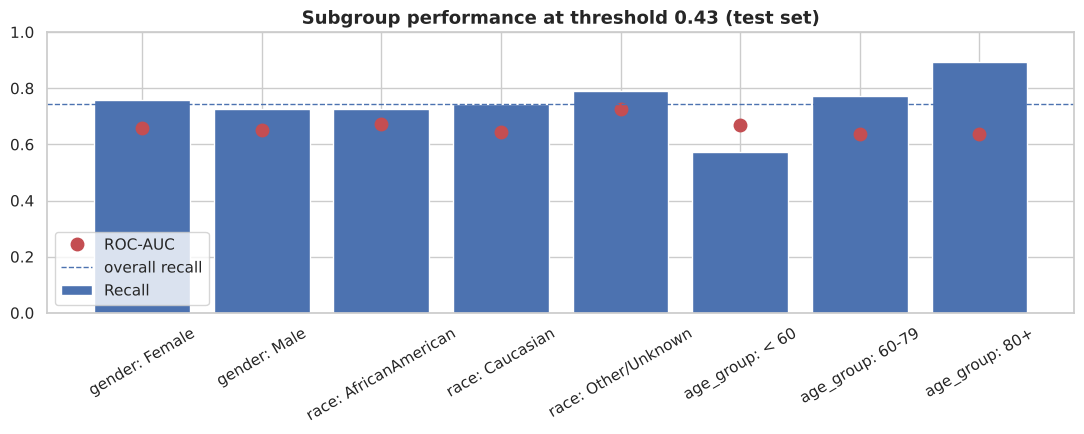

Max recall gap across groups: 0.32


In [40]:
audit = X_test[["gender", "race", "age_num"]].copy()
audit["age_group"] = pd.cut(audit["age_num"], [0, 60, 80, 100], labels=["< 60", "60-79", "80+"])
audit["race"] = audit["race"].where(audit["race"].isin(["Caucasian", "AfricanAmerican"]), "Other/Unknown")
audit["y"], audit["p"], audit["flag"] = y_test.values, proba_best, pred_thr
fair_rows = []
for attr in ["gender", "race", "age_group"]:
    for level, g in audit.groupby(attr, observed=True):
        if len(g) < 300:
            continue
        fair_rows.append({"attribute": attr, "group": level, "n": len(g), "prevalence": g["y"].mean(),
                          "% flagged": 100 * g["flag"].mean(), "recall": recall_score(g["y"], g["flag"]),
                          "precision": precision_score(g["y"], g["flag"], zero_division=0), "ROC-AUC": roc_auc_score(g["y"], g["p"])})
fairness = pd.DataFrame(fair_rows).set_index(["attribute", "group"])
display(fairness.round(3))

fig, ax = plt.subplots(figsize=(11, 4.5))
labels = [f"{a}: {g}" for a, g in fairness.index]
ax.bar(labels, fairness["recall"], color="#4C72B0", label="Recall")
ax.plot(labels, fairness["ROC-AUC"], "o", color="#C44E52", ms=9, label="ROC-AUC")
ax.axhline(recall_score(y_test, pred_thr), color="#4C72B0", ls="--", lw=1, label="overall recall")
ax.set_ylim(0, 1); ax.set_title(f"Subgroup performance at threshold {THRESHOLD:.2f} (test set)"); ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout(); save_fig("fairness"); plt.show()
print("Max recall gap across groups:", round(fairness["recall"].max() - fairness["recall"].min(), 3))

**Reading.**
- **Sex**: very similar behaviour — recall 0.758 (women) vs 0.725 (men), precision 0.114 vs 0.120, ROC-AUC 0.657 vs 0.650.
- **Race**: recall 0.73–0.79 and precision 0.11–0.13 across African-American, Caucasian and other/unknown patients; ROC-AUC 0.64–0.73 (the 972-patient "other/unknown" group is noisier).
- **Age**: the largest gap (**0.32** in recall): 0.573 under 60, 0.771 at 60–79, **0.893** at 80+. With a single threshold, older patients — who have higher prevalence (10.2 % vs 7.3 %) and higher scores — are flagged much more often (79.7 % vs 35.2 %), while precision is similar (≈ 0.12) and discrimination *within* each age group is comparable (ROC-AUC 0.64–0.67).

**Implication**: a single global threshold under-serves younger patients in terms of recall. Options, to be decided with clinicians: age-specific thresholds (equal opportunity), or accepting the gap because it mirrors genuinely lower risk. In any case these subgroup metrics must be monitored if the model is deployed.

### 8.14 Persisting the model
The full pipeline (preprocessing + model), its calibrated version and the threshold are saved with `joblib`, so new patients can be scored with exactly the same transformations, without retraining.

In [41]:
os.makedirs("models", exist_ok=True)
joblib.dump({"pipeline": best_model, "calibrated": calibrated, "threshold": THRESHOLD, "features": FEATURES},
            "models/readmission_model.joblib")
loaded = joblib.load("models/readmission_model.joblib")
patient = X_test.iloc[[0]]
p = loaded["pipeline"].predict_proba(patient)[0, 1]
print(f"Reloaded. Test patient #0: score = {p:.3f} -> {'FLAG for follow-up' if p >= loaded['threshold'] else 'no flag'} "
      f"(threshold {loaded['threshold']:.2f}); calibrated risk = {loaded['calibrated'].predict_proba(patient)[0, 1]:.1%}")
assert np.allclose(loaded["pipeline"].predict_proba(X_test)[:, 1], proba_best)

Reloaded. Test patient #0: score = 0.768 -> FLAG for follow-up (threshold 0.43); calibrated risk = 25.0%


## 9. Regression: predicting length of stay

### 9.1 Framing and feature availability
Estimating **length of stay** (LOS, `time_in_hospital`, 1–14 days) helps plan beds and staff.

**Leakage warning**: `num_lab_procedures`, `num_medications`, etc. are **counts accumulated during the stay** — the longer the stay, the more tests and drugs. Using them to predict the stay partly uses the answer to predict itself. Two scenarios are therefore compared:

| Scenario | When the prediction is made | Features |
|----------|-----------------------------|----------|
| **A – At admission** (operational) | when the patient arrives | demographics, admission type and source, specialty, diagnosis groups*, prior-year history |
| **B – Retrospective** (explanatory) | at discharge | A + everything from the stay (labs, procedures, medications, results, discharge disposition) |

\* diagnoses are coded at discharge, but the primary diagnosis is usually known (at least approximately) on admission — an approximation flagged as a limitation. The same train/test patients as in section 8 are used.

In [42]:
REG_TARGET = "time_in_hospital"
REG_NUM_A = ["age_num", "number_outpatient", "number_emergency", "number_inpatient"]
REG_CAT_A = ["race", "gender", "admission_type", "admission_source", "medical_specialty",
             "diag_1_group", "diag_2_group", "diag_3_group"]
REG_NUM_B = REG_NUM_A + ["num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses",
                         "n_diabetes_meds", "n_med_changes"]
REG_CAT_B = REG_CAT_A + ["discharge", "max_glu_serum", "A1Cresult", "change", "diabetesMed"] + MEDS_KEPT

yr = df[REG_TARGET]
yr_train, yr_test = yr.loc[X_train.index], yr.loc[X_test.index]
Xr_train, Xr_test = df.loc[X_train.index], df.loc[X_test.index]
print(f"Train: {len(yr_train):,} | Test: {len(yr_test):,}")
print(f"Mean LOS (train) = {yr_train.mean():.2f} d | std = {yr_train.std():.2f} d | median = {yr_train.median():.0f} d")

Train: 55,989 | Test: 13,998
Mean LOS (train) = 4.28 d | std = 2.93 d | median = 3 d


### 9.2 Baseline: simple linear regression
Starting from the variable most correlated with LOS (`num_medications`, section 5.7): $\hat{y} = a \cdot x + b$.

In [43]:
lin_simple = LinearRegression().fit(Xr_train[["num_medications"]], yr_train)
a, b = lin_simple.coef_[0], lin_simple.intercept_
pred_simple = lin_simple.predict(Xr_test[["num_medications"]])
print(f"LOS = {a:.4f} x num_medications + {b:.4f}")
print(f"MAE = {mean_absolute_error(yr_test, pred_simple):.3f} d | RMSE = {np.sqrt(mean_squared_error(yr_test, pred_simple)):.3f} d "
      f"| R² = {r2_score(yr_test, pred_simple):.3f}")

LOS = 0.1652 x num_medications + 1.6860


MAE = 1.975 d | RMSE = 2.593 d | R² = 0.221


**Reading.** LOS ≈ 0.165 × medications + 1.69: each additional drug is associated with **+0.17 day** (about one day per six drugs). This single variable explains **22 %** of the variance (R² 0.221, MAE 1.98 days). Reminder: `num_medications` is partly a **consequence** of the stay length — the model is explanatory, not predictive at admission.

### 9.3 Model comparison
Metrics: **MAE** (mean absolute error, days, robust), **MSE**, **RMSE** (same unit as the target, penalises large errors), **R²** (share of variance explained; 0 = no better than the mean) and **adjusted R²** (penalises the number of columns *p*).

In [44]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def eval_regressor(name, scen, pipe, Xtr, ytr, Xte, yte):
    t0 = time.time(); pipe.fit(Xtr, ytr); secs = time.time() - t0
    pte, ptr = pipe.predict(Xte), pipe.predict(Xtr)
    p = len(pipe.named_steps["prep"].get_feature_names_out()); r2 = r2_score(yte, pte)
    return {"scenario": scen, "model": name, "MAE": mean_absolute_error(yte, pte), "MSE": mean_squared_error(yte, pte),
            "RMSE": np.sqrt(mean_squared_error(yte, pte)), "R²": r2, "adjusted R²": adjusted_r2(r2, len(yte), p),
            "train R²": r2_score(ytr, ptr), "n columns": p, "fit time (s)": secs}, pte

reg_models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Decision tree (depth 8)": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
    "KNN (k=15)": KNeighborsRegressor(n_neighbors=15, n_jobs=-1),
    "Random forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=10, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
scenarios = {"A - admission": (REG_NUM_A, REG_CAT_A), "B - retrospective": (REG_NUM_B, REG_CAT_B)}
reg_rows, reg_preds, reg_pipes = [], {}, {}
for scen, (num, cat) in scenarios.items():
    for name, m in reg_models.items():
        pipe = Pipeline([("prep", make_preprocessor(num, cat)), ("model", clone(m))])
        r, pte = eval_regressor(name, scen, pipe, Xr_train[num + cat], yr_train, Xr_test[num + cat], yr_test)
        reg_rows.append(r); reg_preds[(scen, name)] = pte; reg_pipes[(scen, name)] = pipe
reg_results = pd.DataFrame(reg_rows).set_index(["scenario", "model"])
display(reg_results.style.format("{:.3f}", subset=["MAE", "MSE", "RMSE", "R²", "adjusted R²", "train R²", "fit time (s)"])
        .background_gradient(subset=["RMSE"], cmap="Greens_r").background_gradient(subset=["R²"], cmap="Greens"))

**Reading.**
- **Baseline**: the `DummyRegressor` has RMSE 2.94 days (the target's standard deviation) and R² 0.
- **Scenario A (at admission)**: the best model (gradient boosting) only reaches **R² 0.105** (RMSE 2.78 d, MAE 2.14 d) — with arrival information alone, **length of stay is hard to predict**.
- **Scenario B (retrospective)**: R² rises to **0.441** (RMSE 2.20 d, MAE **1.63 d**) for gradient boosting, ahead of random forest (0.426), linear regression (0.382), the tree (0.360) and KNN (0.338). The +0.34 jump from A to B comes mostly from **in-stay counts**, confirming that they partly encode the duration itself.
- **Adjusted R²** is close to R² (0.436 vs 0.441) since n = 13,998 ≫ p = 122 columns.
- **Overfitting**: linear regression (train 0.389 / test 0.382) and gradient boosting (0.489 / 0.441) are stable; random forest (0.579 / 0.426) and scenario-A KNN (0.165 / 0.048) show a marked train–test gap.

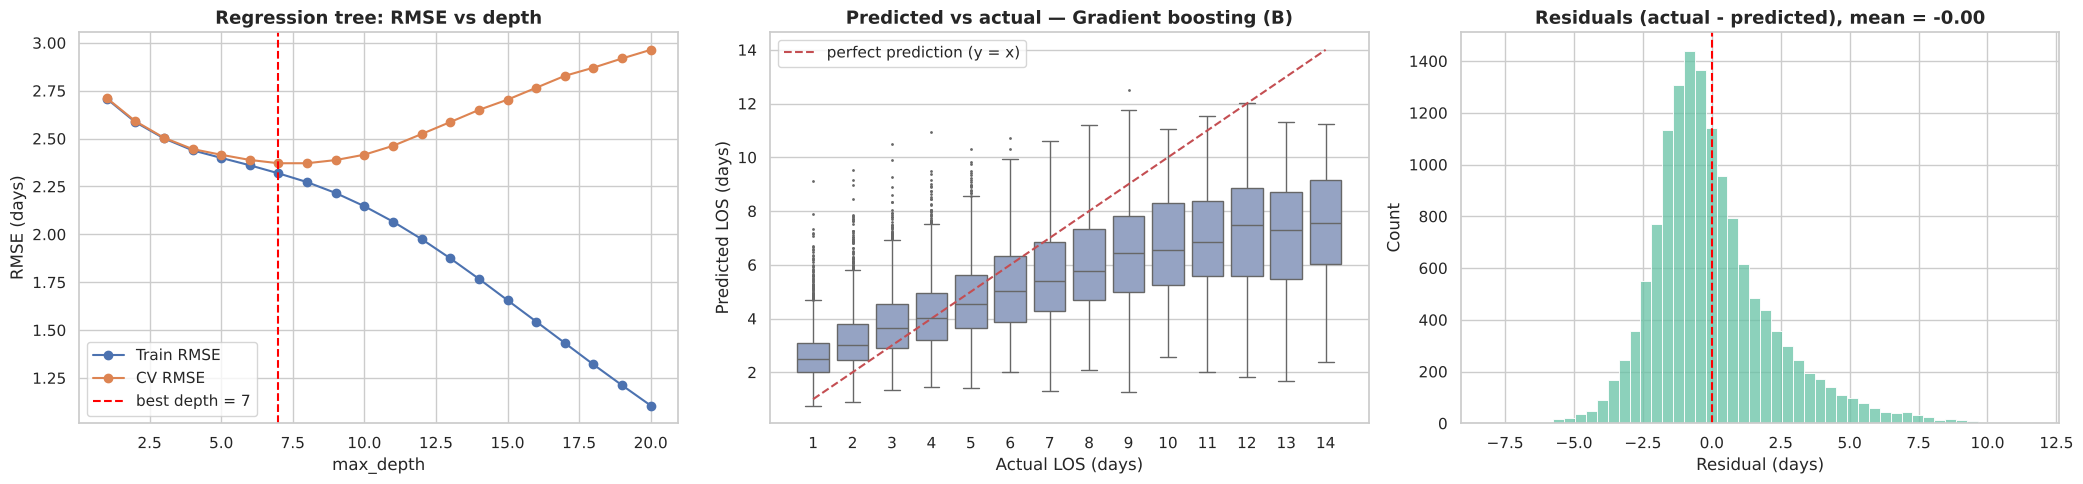

Best tree depth = 7 | CV RMSE = 2.371 d | depth 20: train 1.106 d vs CV 2.963 d
Mean absolute error by actual LOS: {1: 1.66, 2: 1.28, 3: 1.08, 4: 1.02, 5: 1.24, 6: 1.58, 7: 1.9, 8: 2.3, 9: 2.7, 10: 3.29, 11: 4.09, 12: 4.7, 13: 5.73, 14: 6.53}
Std of y_test = 2.938 d (= RMSE of always predicting the mean)


Permutation importance (increase in RMSE, days):
num_medications      0.5415
num_lab_procedures   0.1834
discharge            0.1830
diag_1_group         0.0801
num_procedures       0.0784
medical_specialty    0.0525
admission_source     0.0369
admission_type       0.0338
dtype: float64


In [45]:
reg_tree = Pipeline([("prep", make_preprocessor(REG_NUM_B, REG_CAT_B)), ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))])
depths_r = np.arange(1, 21)
tr, va = validation_curve(reg_tree, Xr_train[REG_NUM_B + REG_CAT_B], yr_train, param_name="model__max_depth",
                          param_range=depths_r, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
best_d = depths_r[(-va.mean(1)).argmin()]
best_reg_key = reg_results.loc["B - retrospective", "RMSE"].idxmin()
pte = reg_preds[("B - retrospective", best_reg_key)]
residuals = yr_test.values - pte

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
axes[0].plot(depths_r, -tr.mean(1), "o-", label="Train RMSE"); axes[0].plot(depths_r, -va.mean(1), "o-", label="CV RMSE")
axes[0].axvline(best_d, color="red", ls="--", label=f"best depth = {best_d}")
axes[0].set_title("Regression tree: RMSE vs depth"); axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("RMSE (days)"); axes[0].legend()
sns.boxplot(x=yr_test.values, y=pte, ax=axes[1], color="#8DA0CB", fliersize=1)
axes[1].plot(range(14), range(1, 15), "r--", label="perfect prediction (y = x)")
axes[1].set_title(f"Predicted vs actual — {best_reg_key} (B)"); axes[1].set_xlabel("Actual LOS (days)"); axes[1].set_ylabel("Predicted LOS (days)"); axes[1].legend()
sns.histplot(residuals, bins=50, ax=axes[2], color="#66C2A5"); axes[2].axvline(0, color="red", ls="--")
axes[2].set_title(f"Residuals (actual - predicted), mean = {residuals.mean():.2f}"); axes[2].set_xlabel("Residual (days)")
plt.tight_layout(); save_fig("regression_diagnostics"); plt.show()

print(f"Best tree depth = {best_d} | CV RMSE = {(-va.mean(1)).min():.3f} d | depth 20: train {-tr.mean(1)[-1]:.3f} d vs CV {-va.mean(1)[-1]:.3f} d")
print("Mean absolute error by actual LOS:", pd.DataFrame({"y": yr_test.values, "e": np.abs(residuals)}).groupby("y")["e"].mean().round(2).to_dict())
print(f"Std of y_test = {yr_test.std():.3f} d (= RMSE of always predicting the mean)")

perm_r = permutation_importance(reg_pipes[("B - retrospective", best_reg_key)], Xr_test[REG_NUM_B + REG_CAT_B], yr_test,
                                scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
print("Permutation importance (increase in RMSE, days):")
print(pd.Series(perm_r.importances_mean, index=REG_NUM_B + REG_CAT_B).sort_values(ascending=False).head(8).round(4))

**Reading.**
- **Tree depth**: training RMSE keeps falling (1.11 d at depth 20) while CV RMSE is minimal (**2.37 d at depth 7**) and climbs back to 2.96 d at depth 20 — worse than predicting the mean.
- **Predicted vs actual**: medians increase with the true LOS but the slope is **well below 1**: short stays are over-estimated (~2.5 d predicted for 1 d) and long stays strongly under-estimated (~7.5 d for 14 d) — **regression to the mean** of an under-informed model.
- **Residuals**: centred on 0 (no global bias) but right-skewed; mean absolute error grows from ~1 day for 3–4-day stays to **6.5 days** for 14-day stays.
- **Gain over the mean**: RMSE 2.20 d vs 2.94 d (−25 %): a real but partial improvement.
- **Drivers**: `num_medications` dominates (+0.54 d RMSE when shuffled), then lab tests and discharge disposition (+0.18 each), primary diagnosis group and number of procedures.

## 10. Clustering: patient segmentation with K-Means

### 10.1 Principle and purpose
Clustering is **unsupervised**: the target is not given to the model. K-Means looks for *k* groups such that each patient is close to its group's **centroid**: place *k* centroids (`k-means++`, several restarts with `n_init`), assign each patient to the nearest one, move each centroid to the mean of its patients, repeat until stable. The criterion minimised is the **inertia** (sum of squared distances to centroids).

**Purpose**: find **care-utilisation profiles** to adapt follow-up programmes, then check *a posteriori* whether these profiles — built without the target — differ in readmission risk.

### 10.2 Feature selection and preparation
- **Numeric** variables describing the patient and the care pathway only: K-Means relies on Euclidean distance, unsuited to one-hot categories.
- **`log(1 + x)`** on the three prior-year counts, which are extremely skewed: otherwise a handful of extreme patients would capture whole clusters.
- **Standardisation** (`StandardScaler`): otherwise `num_lab_procedures` (0–132) would dominate `number_diagnoses` (1–16). It is compared with `MinMaxScaler` below.

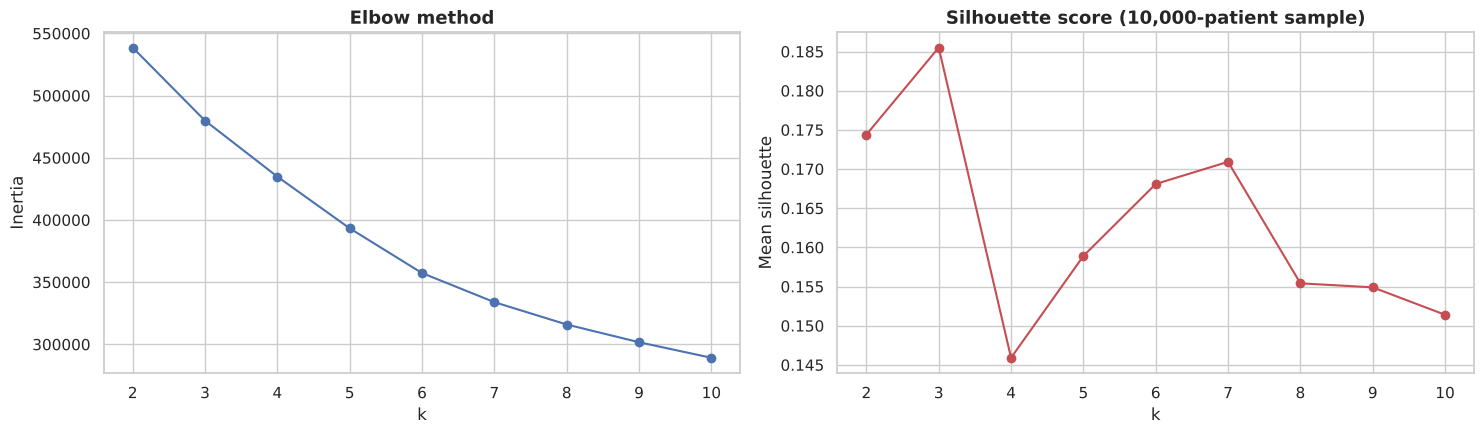

,inertia,inertia drop (%),silhouette
2,"538,607.0440",NaN,0.1740
3,"479,873.5570",10.9050,0.1860
4,"434,840.0710",9.3840,0.1460
5,"393,284.3610",9.5570,0.1590
6,"357,324.8380",9.1430,0.1680
7,"333,916.8220",6.5510,0.1710
8,"315,944.6680",5.3820,0.1550
9,"301,703.2580",4.5080,0.1550
10,"289,187.9930",4.1480,0.1510


Chosen k = 3 | silhouette StandardScaler = 0.186 | MinMaxScaler = 0.233
Cluster sizes (StandardScaler): [ 5032 22135 42820] | (MinMaxScaler): [15139 40388 14460]


In [46]:
CLUST_VARS = ["age_num", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
              "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
Xc = df[CLUST_VARS].astype(float).copy()
for c in ["number_outpatient", "number_emergency", "number_inpatient"]:
    Xc[c] = np.log1p(Xc[c])
Xc_std = StandardScaler().fit_transform(Xc)

ks = range(2, 11)
idx_sil = np.random.RandomState(RANDOM_STATE).choice(len(Xc_std), 10000, replace=False)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc_std)
    inertias.append(km.inertia_); silhouettes.append(silhouette_score(Xc_std[idx_sil], km.labels_[idx_sil]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(ks, inertias, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, silhouettes, "o-", color="#C44E52"); axes[1].set_title("Silhouette score (10,000-patient sample)"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Mean silhouette")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"inertia": inertias, "inertia drop (%)": -100 * pd.Series(inertias).pct_change().values,
                      "silhouette": silhouettes}, index=list(ks)).round(3))

K_OPT = list(ks)[int(np.argmax(silhouettes))]     # k maximising the silhouette (no clear elbow)
kmeans = KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE).fit(Xc_std)
df["cluster"] = kmeans.labels_
Xc_mm = MinMaxScaler().fit_transform(Xc)
km_mm = KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE).fit(Xc_mm)
print(f"Chosen k = {K_OPT} | silhouette StandardScaler = {silhouette_score(Xc_std[idx_sil], kmeans.labels_[idx_sil]):.3f} "
      f"| MinMaxScaler = {silhouette_score(Xc_mm[idx_sil], km_mm.labels_[idx_sil]):.3f}")
print("Cluster sizes (StandardScaler):", np.bincount(kmeans.labels_), "| (MinMaxScaler):", np.bincount(km_mm.labels_))

**Reading.**
- **Elbow**: inertia decreases steadily (−10.9 % from k = 2 to 3, then ≈ −9 % up to k = 6, then ≈ −5 %) — **no clear elbow**.
- **Silhouette**: **maximal at k = 3 (0.186)**, dropping to 0.146 at k = 4 and staying at 0.15–0.17 beyond. **k = 3** is retained.
- **Honest reading**: a silhouette below 0.25 means a **weak cluster structure** — patients form a continuum rather than well-separated groups. The segmentation is useful to **describe** the population, with fuzzy boundaries.
- **StandardScaler vs MinMaxScaler**: MinMax gives a higher silhouette (0.233), but the two values live in different distance spaces and are **not comparable**. With MinMax, the heavy-tailed history variables are squeezed near 0 and the "emergency users" profile disappears (groups then mostly follow length of stay and number of procedures). StandardScaler + log is chosen for **clinical interpretability**.

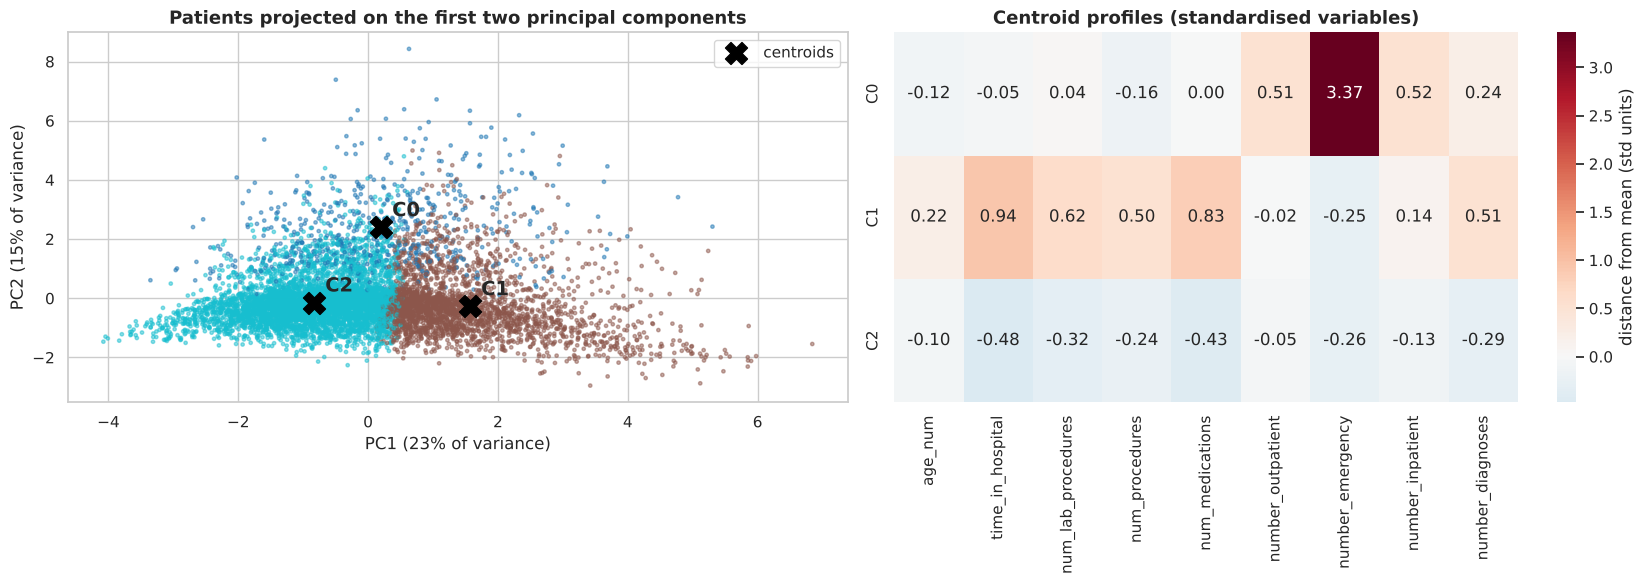

,n,age,los_days,lab_tests,procedures,medications,diagnoses,outpatient,emergency,inpatient,readmission_30d_pct,share_pct,insulin_pct,med_change_pct,discharged_home_pct
C0,5032,63.5200,4.1200,43.7600,1.1400,15.7100,7.7000,0.7200,1.4300,0.4900,12.0400,7.1900,58.1100,52.1900,63.2000
C1,22135,68.9800,7.0100,55.2000,2.3000,22.5400,8.2500,0.2700,0.0000,0.2500,10.9600,31.6300,60.2400,53.9600,48.1200
C2,42820,63.8400,2.8800,36.4000,1.0100,12.1000,6.6400,0.2300,0.0000,0.1000,7.5900,61.1800,45.4600,39.5200,71.2000


Chi-square test cluster x readmission: chi2 = 265.0, p-value = 2.92e-58


In [47]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xp = pca.fit_transform(Xc_std)
centres_p = pca.transform(kmeans.cluster_centers_)
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(Xp), 8000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].scatter(Xp[sample_idx, 0], Xp[sample_idx, 1], c=df["cluster"].values[sample_idx], cmap="tab10", s=6, alpha=0.5)
axes[0].scatter(centres_p[:, 0], centres_p[:, 1], c="black", marker="X", s=250, label="centroids")
for i, (x_, y_) in enumerate(centres_p):
    axes[0].annotate(f"C{i}", (x_, y_), fontsize=14, fontweight="bold", xytext=(8, 8), textcoords="offset points")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)"); axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[0].set_title("Patients projected on the first two principal components"); axes[0].legend()
centres_std = pd.DataFrame(kmeans.cluster_centers_, columns=CLUST_VARS, index=[f"C{i}" for i in range(K_OPT)])
sns.heatmap(centres_std, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "distance from mean (std units)"})
axes[1].set_title("Centroid profiles (standardised variables)")
plt.tight_layout(); save_fig("clusters"); plt.show()

profile = df.groupby("cluster").agg(
    n=("patient_nbr", "size"), age=("age_num", "mean"), los_days=("time_in_hospital", "mean"),
    lab_tests=("num_lab_procedures", "mean"), procedures=("num_procedures", "mean"), medications=("num_medications", "mean"),
    diagnoses=("number_diagnoses", "mean"), outpatient=("number_outpatient", "mean"), emergency=("number_emergency", "mean"),
    inpatient=("number_inpatient", "mean"), readmission_30d_pct=("readmitted_30d", "mean"))
profile["share_pct"] = 100 * profile["n"] / profile["n"].sum()
profile["insulin_pct"] = df.groupby("cluster")["insulin"].apply(lambda s: 100 * (s != "No").mean())
profile["med_change_pct"] = df.groupby("cluster")["change"].apply(lambda s: 100 * (s == "Ch").mean())
profile["discharged_home_pct"] = df.groupby("cluster")["discharge"].apply(lambda s: 100 * (s == "Home").mean())
profile["readmission_30d_pct"] *= 100
profile.index = [f"C{i}" for i in profile.index]
display(profile.round(2))
chi2, pval, _, _ = stats.chi2_contingency(pd.crosstab(df["cluster"], df["readmitted_30d"]))
print(f"Chi-square test cluster x readmission: chi2 = {chi2:.1f}, p-value = {pval:.2e}")

**Three care profiles** (k = 3):

| Cluster | Size | Profile | 30-day readmission |
|---------|------|---------|--------------------|
| **C2 – Short, simple stays** | 42,820 (61 %) | 2.9-day stay, 36 lab tests, 12 drugs, 6.6 diagnoses, almost no prior admissions, mean age 64; 71 % go home | **7.6 %** (lowest) |
| **C1 – Heavy stays** | 22,135 (32 %) | long stay (7.0 d), 55 lab tests, 2.3 procedures, 22.5 drugs, 8.3 diagnoses, older (69); treatment changed in 54 %; only 48 % go home | **11.0 %** |
| **C0 – Frequent emergency users** | 5,032 (7 %) | average stay (4.1 d) but **heavy history**: 1.4 emergency visits (centroid at +3.4 std), 0.7 outpatient and 0.5 inpatient visits in the prior year | **12.0 %** (highest) |

- **PCA view**: PC1 (23 % of variance) is a **stay-intensity** axis (LOS, drugs, labs, diagnoses) separating C2 from C1; PC2 (15 %) is a **prior-utilisation** axis (emergency, inpatient, outpatient) that isolates C0. Clouds touch, consistent with the modest silhouette.
- **External validation**: the target was never used, yet readmission rates differ clearly (7.6 % → 12.0 %, ×1.6); a chi-square test (χ² = 265, p ≈ 3·10⁻⁵⁸) rejects independence between cluster and readmission.

**Operational use**: C0 (7 % of patients) is a natural target for a **community–hospital coordination programme** to prevent repeated emergency visits; C1 calls for **stronger discharge planning** (transfers to care facilities, modified treatments).

## 11. Model card, limitations and next steps

In [48]:
summary = pd.DataFrame({
    "Task": ["Classification (30-day readmission)", "Classification (30-day readmission)",
             "Regression (length of stay)", "Regression (length of stay)", "Clustering"],
    "Model / setting": [f"{FINAL_NAME}, threshold {THRESHOLD:.2f}", "Baseline: majority class",
                        f"{best_reg_key} (B, retrospective)", f"{reg_results.loc['A - admission', 'RMSE'].idxmin()} (A, at admission)",
                        f"K-Means, k = {K_OPT}"],
    "Test-set result": [
        f"ROC-AUC {ci.loc['ROC-AUC', 'estimate']:.3f} [{ci.loc['ROC-AUC', '95% CI low']:.3f}-{ci.loc['ROC-AUC', '95% CI high']:.3f}] | "
        f"PR-AUC {ci.loc['PR-AUC', 'estimate']:.3f} | recall {recall_score(y_test, pred_thr):.3f} | precision {precision_score(y_test, pred_thr):.3f}",
        f"accuracy {clf_results.loc['Dummy (majority)', 'accuracy']:.3f} | recall 0.000",
        f"MAE {reg_results.loc[('B - retrospective', best_reg_key), 'MAE']:.2f} d | RMSE {reg_results.loc[('B - retrospective', best_reg_key), 'RMSE']:.2f} d | "
        f"R² {reg_results.loc[('B - retrospective', best_reg_key), 'R²']:.3f}",
        f"RMSE {reg_results.loc['A - admission', 'RMSE'].min():.2f} d | R² {reg_results.loc['A - admission', 'R²'].max():.3f}",
        f"silhouette {silhouette_score(Xc_std[idx_sil], kmeans.labels_[idx_sil]):.3f} | readmission "
        f"{profile['readmission_30d_pct'].min():.1f} % to {profile['readmission_30d_pct'].max():.1f} % across clusters",
    ],
})
display(summary.style.hide(axis="index"))

Task,Model / setting,Test-set result
Classification (30-day readmission),"Gradient boosting (tuned), threshold 0.43",ROC-AUC 0.653 [0.638-0.670] | PR-AUC 0.179 | recall 0.742 | precision 0.116
Classification (30-day readmission),Baseline: majority class,accuracy 0.910 | recall 0.000
Regression (length of stay),"Gradient boosting (B, retrospective)",MAE 1.63 d | RMSE 2.20 d | R² 0.441
Regression (length of stay),"Gradient boosting (A, at admission)",RMSE 2.78 d | R² 0.105
Clustering,"K-Means, k = 3",silhouette 0.186 | readmission 7.6 % to 12.0 % across clusters


### 11.1 Model card (classification model)

| Item | Description |
|------|-------------|
| **Intended use** | Research and education. Rank diabetic inpatients at discharge by 30-day readmission risk to **prioritise** low-cost follow-up (calls, early visits). Not a diagnostic tool; not validated for clinical use. |
| **Not intended for** | Denying care or resources; use outside US-like settings or on post-2008 data without re-validation; individual clinical decisions without clinician review. |
| **Training data** | UCI *Diabetes 130-US Hospitals 1999–2008*; first encounter of each patient (69,987 patients) after excluding deaths and hospice; 80/20 stratified split (55,989 / 13,998). |
| **Model** | `HistGradientBoostingClassifier` (balanced class weights, tuned by randomized search on CV PR-AUC) in a scikit-learn pipeline (median imputation, scaling, one-hot encoding with rare-level grouping); isotonic calibration (5-fold) for probability outputs. |
| **Performance (test)** | ROC-AUC 0.653 [0.638–0.670]; PR-AUC 0.179 [0.163–0.199] (chance 0.090); at threshold 0.43: recall 0.742, precision 0.116, 57 % flagged; top decile: 21.2 % readmitted (2.4× average); calibrated Brier 0.079 (reference 0.082). |
| **Fairness** | Comparable recall across sex and race; recall rises with age (0.57 < 60 → 0.89 at 80+) under a single threshold. |
| **Main limitations** | Old (1999–2008, ICD-9) US administrative data; readmissions to other hospitals unobserved; no vital signs, detailed labs or social determinants; associations, not causes; single-source internal validation only. |

### 11.2 Conclusions
1. **Rigour matters more than the algorithm.** One row per patient, leakage-safe pipelines, CV-only model selection and appropriate metrics shaped the results more than model choice: seven algorithms fall within a few hundredths of ROC-AUC, and tuning changed nothing beyond noise.
2. **The model concentrates risk.** It does not predict readmission precisely (ROC-AUC 0.65), but it ranks well enough to **prioritise**: the top risk decile has 2.4× the average readmission rate, and decision curve analysis shows positive net benefit for low-cost interventions.
3. **Scores and probabilities are different things.** Class weighting inflates scores (mean 46 % for a 9 % reality); calibration is mandatory before any risk is communicated.
4. **The care pathway is the signal.** Discharge disposition and prior admissions dominate every explanation method; diabetes biomarkers contribute little.
5. **Length of stay** is hard to predict at admission (R² 0.10); retrospective models (R² 0.44) are mostly explanatory.
6. **Three care profiles** — simple stays, heavy stays, frequent emergency users — differ in readmission risk (7.6 % → 12.0 %) and suggest targeted programmes.

### 11.3 Limitations
- **Dataset age and context**: 1999–2008 US data; treatments (SGLT2 inhibitors, GLP-1 agonists), coding (ICD-9 → ICD-10 in 2015) and readmission policies have changed since. The model cannot be used as is today.
- **Outcome definition**: only readmissions within the same network are observed; some "negatives" may be readmissions elsewhere.
- **Feature availability**: no vital signs, detailed lab values or social determinants; diagnoses are coded at discharge, which makes the at-admission regression scenario approximate.
- **Validation**: internal (random split of one source). Temporal and external validation are needed before any real use.

### 11.4 Next steps
- Use **all encounters** with patient-grouped cross-validation (`GroupKFold`) and history features (time since last admission, number of previous readmissions).
- **SMOTENC** or cost-sensitive learning with a cost matrix defined with clinicians.
- **Temporal validation** and recalibration on recent data (ICD-10), then prospective monitoring of calibration and subgroup metrics.
- Explore **age-specific thresholds** to equalise recall, and report per-alert **SHAP explanations** to clinicians.